## Design choice: panel tilt 0° (flat)

**Criterion:** smallest land-use index needed to cover the annual demand of Utsira (see #9; a higher "Landen" index means more energy per unit of land use).

**Why 0°:** tilted rows need spacing to avoid shading, so land use grows quickly with tilt. The Landen index is 245.6 at 0° and 29.2 at 40°.

**Trade-off:** flat panels collect less sun per m², so they need about 15,200 m² of panel area against about 12,500 m² at 40°.

All later cells use the 0° data (variables ending in 0).

In [1]:
#0. Call the code commands

import pvlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from scipy.optimize import least_squares

### #1 Hourly electricity demand of Utsira

**Why:** everything starts from what the island needs each hour. The PV area and the battery size are all measured against this.

**Logic:** read `UtsiraHC2025_1.xlsx` and take every 4th row from row 2 (column `Hourlyneeds`). Store the values in `valueneed` (kWh per hour, equal to kW). Then `peak_power_need` is the largest hourly value and `avneed` is the mean.

**Assumptions:**
1. The file has 4 rows per hour, so every 4th row gives one value per hour. *(check)*
2. Year 2025, 365 days, no missing hours.
3. Each value is energy in one hour, so 1 kWh per hour = 1 kW.

**Check:** `valueneed` must have exactly 8,760 values, and the printed peak is 660.9 kW.

In [2]:
#1. Get energy needs hourly in general (could change the location)

timegen = []
valueneed = []
need = pd.read_excel("UtsiraHC2025_1.xlsx")
for i in range(2, len(need) - 4, 4):
    time = need.iloc[i]["Time"]
    timegen.append(time)
    value = need.iloc[i]["Hourlyneeds"]
    valueneed.append(value)
peak_power_need = max(valueneed)
print(peak_power_need)
avneed = sum(valueneed) / len(valueneed)

660.938


### #2 Weather and sunlight data (Open-Meteo)

**Why:** PV output depends on the sunlight falling on the tilted panel and on the air temperature, hour by hour.

**Logic:** for each tilt from 0° to 60° in 5° steps, two CSV files are read (`skiprows=3` skips the header lines):
- `...19m{tilt}tilt.csv` = **south-facing** panel, the main collector
- `...19m-{tilt}tilt.csv` = **north-facing** panel, the second row (the dash is a naming habit, not a negative tilt)

From each file the notebook keeps the time (`timeg`), the global tilted irradiance in W/m² (`grad`), the air temperature in °C (`temp`) and the yearly sum of irradiance (`all`).

**Assumptions:**
1. Open-Meteo archive data (model-based, not measured on site) for 59.297 N, 4.898 E, elevation 19 m, year 2025, time in GMT.
2. Irradiance on the tilted plane is the value Open-Meteo gives (direct + diffuse + ground-reflected).
3. No shading from objects, snow or dirt at this stage.

**Check:** the printed yearly sums for the south files rise to a peak at 40° (1,262,323) and then fall: 10° gives 1,132,502 and 60° gives 1,211,474 (Wh/m²).

In [3]:
#2. Open files and get needed datas

#00. 0 degree angle (flat)

surface_tilt_00 = 0
tilt0 = pd.read_csv("open-meteo-59.30N4.90E19m0tilt.csv", skiprows=3)

timeg0 = tilt0["time"]

grad0 = tilt0["global_tilted_irradiance (W/m²)"]
grad0 = pd.to_numeric(grad0)
all0 = grad0.sum()

temp0 = tilt0["temperature_2m (°C)"]
temp0 = pd.to_numeric(temp0)

#00.1 0 but azimuth 0 degree (a flat panel is the same on both sides)

tilt_0 = pd.read_csv("open-meteo-59.30N4.90E19m-0tilt.csv", skiprows=3)

timeg_0 = tilt_0["time"]

grad_0 = tilt_0["global_tilted_irradiance (W/m²)"]
grad_0 = pd.to_numeric(grad_0)
all_0 = grad_0.sum()

temp_0 = tilt_0["temperature_2m (°C)"]
temp_0 = pd.to_numeric(temp_0)
# If you have no -0tilt file, use: tilt_0 = tilt0; grad_0 = grad0; all_0 = all0; temp_0 = temp0


#05. 5 degree angle

surface_tilt_05 = 5
tilt5 = pd.read_csv("open-meteo-59.30N4.90E19m5tilt.csv", skiprows=3)

timeg5 = tilt5["time"]

grad5 = tilt5["global_tilted_irradiance (W/m²)"]
grad5 = pd.to_numeric(grad5)
all5 = grad5.sum()

temp5 = tilt5["temperature_2m (°C)"]
temp5 = pd.to_numeric(temp5)

#05.1 5 but azimuth 0 degree

tilt_5 = pd.read_csv("open-meteo-59.30N4.90E19m-5tilt.csv", skiprows=3)

timeg_5 = tilt_5["time"]

grad_5 = tilt_5["global_tilted_irradiance (W/m²)"]
grad_5 = pd.to_numeric(grad_5)
all_5 = grad_5.sum()

temp_5 = tilt_5["temperature_2m (°C)"]
temp_5 = pd.to_numeric(temp_5)
#a. 10 degree angle

surface_tilt_a = 10
tilt10 = pd.read_csv("open-meteo-59.30N4.90E19m10tilt.csv", skiprows=3)

timeg10 = tilt10["time"]

grad10 = tilt10["global_tilted_irradiance (W/m²)"]
grad10 = pd.to_numeric(grad10)
all10 = grad10.sum()

temp10 = tilt10["temperature_2m (°C)"]
temp10 = pd.to_numeric(temp10)

#a.1 10 but azimuth 0 degree

tilt_10 = pd.read_csv("open-meteo-59.30N4.90E19m-10tilt.csv", skiprows=3)

timeg_10 = tilt_10["time"]

grad_10 = tilt_10["global_tilted_irradiance (W/m²)"]
grad_10 = pd.to_numeric(grad_10)
all_10 = grad_10.sum()

temp_10 = tilt_10["temperature_2m (°C)"]
temp_10 = pd.to_numeric(temp_10)


#b. 15 degree angle

surface_tilt_b = 15
tilt15 = pd.read_csv("open-meteo-59.30N4.90E19m15tilt.csv", skiprows=3)

timeg15 = tilt15["time"]

grad15 = tilt15["global_tilted_irradiance (W/m²)"]
grad15 = pd.to_numeric(grad15)
all15 = grad15.sum()

temp15 = tilt15["temperature_2m (°C)"]
temp15 = pd.to_numeric(temp15)

#b.1 15 but azimuth 0 degree

tilt_15 = pd.read_csv("open-meteo-59.30N4.90E19m-15tilt.csv", skiprows=3)

timeg_15 = tilt_15["time"]

grad_15 = tilt_15["global_tilted_irradiance (W/m²)"]
grad_15 = pd.to_numeric(grad_15)
all_15 = grad_15.sum()

temp_15 = tilt_15["temperature_2m (°C)"]
temp_15 = pd.to_numeric(temp_15)


#c. 20 degree angle

surface_tilt_c = 20
tilt20 = pd.read_csv("open-meteo-59.30N4.90E19m20tilt.csv", skiprows=3)

timeg20 = tilt20["time"]

grad20 = tilt20["global_tilted_irradiance (W/m²)"]
grad20 = pd.to_numeric(grad20)
all20 = grad20.sum()

temp20 = tilt20["temperature_2m (°C)"]
temp20 = pd.to_numeric(temp20)

#c.1 20 but azimuth 0 degree

tilt_20 = pd.read_csv("open-meteo-59.30N4.90E19m-20tilt.csv", skiprows=3)

timeg_20 = tilt_20["time"]

grad_20 = tilt_20["global_tilted_irradiance (W/m²)"]
grad_20 = pd.to_numeric(grad_20)
all_20 = grad_20.sum()

temp_20 = tilt_20["temperature_2m (°C)"]
temp_20 = pd.to_numeric(temp_20)


#d. 25 degree angle

surface_tilt_d = 25
tilt25 = pd.read_csv("open-meteo-59.30N4.90E19m25tilt.csv", skiprows=3)

timeg25 = tilt25["time"]

grad25 = tilt25["global_tilted_irradiance (W/m²)"]
grad25 = pd.to_numeric(grad25)
all25 = grad25.sum()

temp25 = tilt25["temperature_2m (°C)"]
temp25 = pd.to_numeric(temp25)

#d.1 25 but azimuth 0 degree

tilt_25 = pd.read_csv("open-meteo-59.30N4.90E19m-25tilt.csv", skiprows=3)

timeg_25 = tilt_25["time"]

grad_25 = tilt_25["global_tilted_irradiance (W/m²)"]
grad_25 = pd.to_numeric(grad_25)
all_25 = grad_25.sum()

temp_25 = tilt_25["temperature_2m (°C)"]
temp_25 = pd.to_numeric(temp_25)


#e. 30 degree angle

surface_tilt_e = 30
tilt30 = pd.read_csv("open-meteo-59.30N4.90E19m30tilt.csv", skiprows=3)

timeg30 = tilt30["time"]

grad30 = tilt30["global_tilted_irradiance (W/m²)"]
grad30 = pd.to_numeric(grad30)
all30 = grad30.sum()

temp30 = tilt30["temperature_2m (°C)"]
temp30 = pd.to_numeric(temp30)

#e.1 30 but azimuth 0 degree

tilt_30 = pd.read_csv("open-meteo-59.30N4.90E19m-30tilt.csv", skiprows=3)

timeg_30 = tilt_30["time"]

grad_30 = tilt_30["global_tilted_irradiance (W/m²)"]
grad_30 = pd.to_numeric(grad_30)
all_30 = grad_30.sum()

temp_30 = tilt_30["temperature_2m (°C)"]
temp_30 = pd.to_numeric(temp_30)


#f. 35 degree angle

surface_tilt_f = 35
tilt35 = pd.read_csv("open-meteo-59.30N4.90E19m35tilt.csv", skiprows=3)

timeg35 = tilt35["time"]

grad35 = pd.to_numeric(tilt35["global_tilted_irradiance (W/m²)"])
all35 = grad35.sum()
temp35 = pd.to_numeric(tilt35["temperature_2m (°C)"])

#f.1 35 but azimuth 0 degree

tilt_35 = pd.read_csv("open-meteo-59.30N4.90E19m-35tilt.csv", skiprows=3)

timeg_35 = tilt_35["time"]

grad_35 = pd.to_numeric(tilt_35["global_tilted_irradiance (W/m²)"])
all_35 = grad_35.sum()
temp_35 = pd.to_numeric(tilt_35["temperature_2m (°C)"])


#g. 40 degree angle

surface_tilt_g = 40
tilt40 = pd.read_csv("open-meteo-59.30N4.90E19m40tilt.csv", skiprows=3)

timeg40 = tilt40["time"]

grad40 = tilt40["global_tilted_irradiance (W/m²)"]
grad40 = pd.to_numeric(grad40)
all40 = grad40.sum()

temp40 = tilt40["temperature_2m (°C)"]
temp40 = pd.to_numeric(temp40)

#g.1 40 but azimuth 0 degree

tilt_40 = pd.read_csv("open-meteo-59.30N4.90E19m-40tilt.csv", skiprows=3)

timeg_40 = tilt_40["time"]

grad_40 = tilt_40["global_tilted_irradiance (W/m²)"]
grad_40 = pd.to_numeric(grad_40)
all_40 = grad_40.sum()

temp_40 = tilt_40["temperature_2m (°C)"]
temp_40 = pd.to_numeric(temp_40)


#h. 45 degree angle

surface_tilt_h = 45
tilt45 = pd.read_csv("open-meteo-59.30N4.90E19m45tilt.csv", skiprows=3)

timeg45 = tilt45["time"]

grad45 = tilt45["global_tilted_irradiance (W/m²)"]
grad45 = pd.to_numeric(grad45)
all45 = grad45.sum()

temp45 = tilt45["temperature_2m (°C)"]
temp45 = pd.to_numeric(temp45)

#h.1 45 but azimuth 0 degree

tilt_45 = pd.read_csv("open-meteo-59.30N4.90E19m-45tilt.csv", skiprows=3)

timeg_45 = tilt_45["time"]

grad_45 = tilt_45["global_tilted_irradiance (W/m²)"]
grad_45 = pd.to_numeric(grad_45)
all_45 = grad_45.sum()

temp_45 = tilt_45["temperature_2m (°C)"]
temp_45 = pd.to_numeric(temp_45)


#i. 50 degree angle

surface_tilt_i = 50
tilt50 = pd.read_csv("open-meteo-59.30N4.90E19m50tilt.csv", skiprows=3)

timeg50 = tilt50["time"]

grad50 = tilt50["global_tilted_irradiance (W/m²)"]
grad50 = pd.to_numeric(grad50)
all50 = grad50.sum()

temp50 = tilt50["temperature_2m (°C)"]
temp50 = pd.to_numeric(temp50)

#i.1 50 but azimuth 0 degree

tilt_50 = pd.read_csv("open-meteo-59.30N4.90E19m-50tilt.csv", skiprows=3)

timeg_50 = tilt_50["time"]

grad_50 = tilt_50["global_tilted_irradiance (W/m²)"]
grad_50 = pd.to_numeric(grad_50)
all_50 = grad_50.sum()

temp_50 = tilt_50["temperature_2m (°C)"]
temp_50 = pd.to_numeric(temp_50)


#j. 55 degree angle

surface_tilt_j = 55
tilt55 = pd.read_csv("open-meteo-59.30N4.90E19m55tilt.csv", skiprows=3)

timeg55 = tilt55["time"]

grad55 = tilt55["global_tilted_irradiance (W/m²)"]
grad55 = pd.to_numeric(grad55)
all55 = grad55.sum()

temp55 = tilt55["temperature_2m (°C)"]
temp55 = pd.to_numeric(temp55)

#j.1 55 but azimuth 0 degree

tilt_55 = pd.read_csv("open-meteo-59.30N4.90E19m-55tilt.csv", skiprows=3)

timeg_55 = tilt_55["time"]

grad_55 = tilt_55["global_tilted_irradiance (W/m²)"]
grad_55 = pd.to_numeric(grad_55)
all_55 = grad_55.sum()

temp_55 = tilt_55["temperature_2m (°C)"]
temp_55 = pd.to_numeric(temp_55)


#k. 60 degree angle

surface_tilt_k = 60
tilt60 = pd.read_csv("open-meteo-59.30N4.90E19m60tilt.csv", skiprows=3)

timeg60 = tilt60["time"]

grad60 = tilt60["global_tilted_irradiance (W/m²)"]
grad60 = pd.to_numeric(grad60)
all60 = grad60.sum()

temp60 = tilt60["temperature_2m (°C)"]
temp60 = pd.to_numeric(temp60)

#k.1 60 but azimuth 0 degree

tilt_60 = pd.read_csv("open-meteo-59.30N4.90E19m-60tilt.csv", skiprows=3)

timeg_60 = tilt_60["time"]

grad_60 = tilt_60["global_tilted_irradiance (W/m²)"]
grad_60 = pd.to_numeric(grad_60)
all_60 = grad_60.sum()

temp_60 = tilt_60["temperature_2m (°C)"]
temp_60 = pd.to_numeric(temp_60)


print(all10, all15, all20, all25, all30, all35, all40, all45, all50, all55, all60)



1132501.6 1170266.2 1201803.6 1226989.8 1245601.9 1257446.0 1262322.9 1259946.8 1250496.4 1234278.9 1211474.4


### #3 Efficiency and loss factors

**Why:** these factors turn sunlight into the electricity that reaches the battery and the load.

| Name | Value | Meaning |
|---|---|---|
| `effpv` | 0.20 | PV module efficiency |
| `effin` | 0.96 | inverter efficiency |
| `effmppt` | 0.99 | MPPT (maximum power point tracking) efficiency |
| `efflossop` | 0.96 | losses during operation (state what you include, e.g. dirt, mismatch) |
| `gmmals` | -0.003 per °C | power change per °C of temperature above 25 °C |
| `effsys` | 0.96 | defined but **not used** in the notebook |

**Assumptions:** typical engineering values, not measurements of the real plant.
- `effpv = 0.20` is below the efficiency implied by the datasheet, 450 W / (1.762 m x 1.134 m) = about 22.5 % at standard test conditions. So this is conservative.
- `gmmals` = -0.3 % per °C is the module's power temperature coefficient.

In [4]:
#3. Write needed  efficiencies

effpv = 0.20
effin = 0.96
effsys = 0.96
effmppt = 0.99
efflossop = 0.96
gmmals = -0.003

### #4-#5 Simple hourly DC power per m² of panel

**Why:** a quick first estimate that lets me compare all tilts before using the detailed pvlib model in #5.2. It is also the basis for the panel area (#8) and the battery sizing (#10).

**Logic:**
1. `df` collects the irradiance of every tilt and the demand in one table of 8,760 rows.
2. Irradiance is divided by 1000 to convert W/m² to kW/m² (`radunit_XX`).
3. DC power per m² of panel in each hour:

$$P_{dc} = G \cdot \eta_{pv} \cdot \left[1 + \gamma\,(T_{air} - 25)\right]$$

G = irradiance on the tilted plane [kW/m²], $\eta_{pv}$ = `effpv`, $\gamma$ = `gmmals` = -0.003 per °C, $T_{air}$ = air temperature [°C].

**Units:** `PdcXX` is kW per m² of panel (= kWh per m² per hour). `PdcXX.sum()` is the yearly energy per m².

**Assumptions:**
1. The cell temperature equals the air temperature. In sunshine the cell is warmer, so output is slightly overestimated here. #5.2 corrects this with the Faiman model.
2. Efficiency does not depend on the irradiance level.
3. Reference temperature is 25 °C.
4. Inverter, MPPT and operating losses are not applied here. They are applied in #10.

In [5]:
#4. Create dataframe for simplification

df = pd.DataFrame({
    "time": np.array(timeg35),
    "radiation0": np.array(grad0),
    "radiation5": np.array(grad5),
    "radiation10": np.array(grad10),
    "radiation15": np.array(grad15),
    "radiation20": np.array(grad20),
    "radiation25": np.array(grad25),
    "radiation30": np.array(grad30),
    "radiation35": np.array(grad35),
    "radiation40": np.array(grad40),
    "radiation45": np.array(grad45),
    "radiation50": np.array(grad50),
    "radiation55": np.array(grad55),
    "radiation60": np.array(grad60),
    "demand": np.array(valueneed)
})

#a. Change it into KW
radunit_0  = df["radiation0"] /1000
radunit_5  = df["radiation5"] /1000
radunit_10 = df["radiation10"]/1000
radunit_15 = df["radiation15"]/1000
radunit_20 = df["radiation20"]/1000
radunit_25 = df["radiation25"]/1000
radunit_30 = df["radiation30"]/1000
radunit_35 = df["radiation35"]/1000
radunit_40 = df["radiation40"]/1000
radunit_45 = df["radiation45"]/1000
radunit_50 = df["radiation50"]/1000
radunit_55 = df["radiation55"]/1000
radunit_60 = df["radiation60"]/1000

In [6]:
#5. Calculate initial power with temperature loss

radunit_0 = radunit_0.reset_index(drop=True)
temp0 = temp0.reset_index(drop=True)

radunit_5 = radunit_5.reset_index(drop=True)
temp5 = temp5.reset_index(drop=True)

radunit_35 = radunit_35.reset_index(drop=True)
temp35 = temp35.reset_index(drop=True)

radunit_10 = radunit_10.reset_index(drop=True)
temp10 = temp10.reset_index(drop=True)

radunit_15 = radunit_15.reset_index(drop=True)
temp15 = temp15.reset_index(drop=True)

radunit_20 = radunit_20.reset_index(drop=True)
temp20 = temp20.reset_index(drop=True)

radunit_25 = radunit_25.reset_index(drop=True)
temp25 = temp25.reset_index(drop=True)

radunit_30 = radunit_30.reset_index(drop=True)
temp30 = temp30.reset_index(drop=True)

radunit_40 = radunit_40.reset_index(drop=True)
temp40 = temp40.reset_index(drop=True)

radunit_45 = radunit_45.reset_index(drop=True)
temp45 = temp45.reset_index(drop=True)

radunit_50 = radunit_50.reset_index(drop=True)
temp50 = temp50.reset_index(drop=True)

radunit_55 = radunit_55.reset_index(drop=True)
temp55 = temp55.reset_index(drop=True)

radunit_60 = radunit_60.reset_index(drop=True)
temp60 = temp60.reset_index(drop=True)

Pdc0 = radunit_0 * effpv * (1 + gmmals * (temp0 - 25))

Pdc5 = radunit_5 * effpv * (1 + gmmals * (temp5 - 25))

Pdc10 = radunit_10 * effpv * (1 + gmmals * (temp10 - 25))

Pdc15 = radunit_15 * effpv * (1 + gmmals * (temp15 - 25))

Pdc20 = radunit_20 * effpv * (1 + gmmals * (temp20 - 25))

Pdc25 = radunit_25 * effpv * (1 + gmmals * (temp25 - 25))

Pdc30 = radunit_30 * effpv * (1 + gmmals * (temp30 - 25))

Pdc35 = radunit_35 * effpv * (1 + gmmals * (temp35 - 25))

Pdc40 = radunit_40 * effpv * (1 + gmmals * (temp40 - 25))

Pdc45 = radunit_45 * effpv * (1 + gmmals * (temp45 - 25))

Pdc50 = radunit_50 * effpv * (1 + gmmals * (temp50 - 25))

Pdc55 = radunit_55 * effpv * (1 + gmmals * (temp55 - 25))

Pdc60 = radunit_60 * effpv * (1 + gmmals * (temp60 - 25))



### #5.1 Single-diode model: solving the I-V behaviour by hand

**Why:** to understand the physics before using a library. I solve the equations myself here, then compare with pvlib in #5.2.

**Logic:** the module (JA Solar JAM54D41-450/LB, 450 W, 54 cells in series) is a current source in parallel with a diode and a shunt resistor, plus a series resistor:

$$I = I_L - I_0\left[e^{(V+IR_s)/a}-1\right] - \frac{V+IR_s}{R_{sh}}, \qquad a = n\,N_s\,\frac{k_B T}{q}$$

The four unknowns $I_L, I_0, R_s, R_{sh}$ come from four datasheet conditions:
1. Short circuit: V = 0, I = I_sc (14.48 A)
2. Open circuit: I = 0, V = V_oc (39.30 V)
3. Maximum power point: V = V_mp (32.82 V), I = I_mp (13.71 A)
4. At the maximum power point dP/dV = 0, so $I_{mp} + V_{mp}\,dI/dV = 0$

`least_squares` solves the four equations, working in log space so all values stay positive.

**Assumptions:**
1. Ideality factor n = 1, which gives a = 1.387 V at 25 °C.
2. Datasheet values at standard test conditions (1000 W/m², 25 °C).
3. All 54 cells behave identically.

**Check:** the four residuals printed at the end must be around 1e-14. Yours are 8.6e-16 to 5.6e-14, so the fit satisfies all four conditions.

In [7]:
#5.1 Use equivalent circuit for the I and U mpp behiviour

#JA Solar JAM54D41-450/LB, rated at 450 W
#a. Manufacturers reference values

P_mp = 450 #W (needs kW!)
V_mp = 32.82 #V
I_mp = 13.71 #A
V_oc = 39.30 #V
I_sc = 14.48 #A
gmmals = -0.003 #/C
beta_voc = - 0.00260 #V/C
alpha_sc = 0.00046 #A/C
cells_in_series = 54
temp_ref = 25
irrad_ref = 1000
# Physical constants
k_B = 1.380649e-23  # Boltzmann constant, J/K
q = 1.602176634e-19 # Elementary charge, C

#b. Understanding basics by manual calculation

P_pm_calc = V_mp * I_mp

# Convert reference temperature to kelvin
temp_ref_K = temp_ref + 273.15

# Calculate diode voltage parameter
n = 1.0
a = n * cells_in_series * k_B * temp_ref_K / q

# b.1 Define the four conditions

print(f"Diode voltage parameter: {a:.8f} V")

def four_conditions(params):

    I_L, I_0, R_s, R_sh = params

    # Condition 1: Short circuit
    V_internal_sc = I_sc * R_s

    f1 = (I_L - I_0 * np.expm1(V_internal_sc / a) - V_internal_sc / R_sh - I_sc)

    # Condition 2: Open circuit
    V_internal_oc = V_oc

    f2 = (I_L - I_0 * np.expm1(V_internal_oc / a) - V_internal_oc / R_sh)

    # Condition 3: Maximum-power point
    V_internal_mp = V_mp + I_mp * R_s

    f3 = (I_L - I_0 * np.expm1(V_internal_mp / a) - V_internal_mp / R_sh - I_mp)

    # Condition 4: Maximum-power derivative
    g_mp = (I_0 * np.exp(V_internal_mp / a) / a + 1 / R_sh)

    dI_dV = -g_mp / (1 + R_s * g_mp)

    f4 = I_mp + V_mp * dI_dV

    # Scale residuals to comparable magnitudes
    return np.array([
        f1 / I_sc,
        f2 / I_sc,
        f3 / I_sc,
        f4 / I_mp
    ])


# b.2 Initial guesses

initial_guesses = [
    14.48,       # I_L (A)
    7.224e-12,   # I_0 (A)
    0.15,        # R_s (ohm)
    200.0        # R_sh (ohm)
]

# b.3 Numerical solution

# Calculate the four unknown parameters
result = least_squares(
    lambda x: four_conditions(np.exp(x)),
    np.log(initial_guesses)
)

# Extract the calculated parameters
I_L, I_0, R_s, R_sh = np.exp(result.x)

# b.4 Display results

print("\n===== EXTRACTED PARAMETERS =====")

print(f"I_L  = {I_L:.8f} A")
print(f"I_0  = {I_0:.8e} A")
print(f"R_s  = {R_s:.8f} ohm")
print(f"R_sh = {R_sh:.8f} ohm")

print("\n===== CONDITION RESIDUALS =====")

for i, residual in enumerate(
    four_conditions(np.exp(result.x)), 1
):
    print(f"Condition {i}: {residual:.8e}")



Diode voltage parameter: 1.38739927 V

===== EXTRACTED PARAMETERS =====
I_L  = 14.49071639 A
I_0  = 7.13503234e-12 A
R_s  = 0.15385311 ohm
R_sh = 207.88659475 ohm

===== CONDITION RESIDUALS =====
Condition 1: 8.58736041e-16
Condition 2: -5.59520202e-15
Condition 3: -7.23791806e-15
Condition 4: -5.61022984e-14


### #5.2 Detailed hourly PV output (pvlib single-diode + Faiman cell temperature)

**Why:** the simple model in #5 uses air temperature and a fixed efficiency. This one accounts for how the cell really heats up and how the I-V curve changes with sunlight and temperature.

**Model / source:**
- De Soto et al. (2006) five-parameter single-diode model, through pvlib: `fit_desoto` extracts the parameters from the datasheet, `calcparams_desoto` adjusts them to each hour, `singlediode` solves the I-V curve and the maximum power point.
- Faiman (2008) cell-temperature model with pvlib's default coefficients.

**Logic:**
1. Fit the parameters at standard test conditions (1000 W/m², 25 °C) and check they reproduce the datasheet.
2. Cell temperature for every hour:

$$T_{cell} = T_{air} + \frac{G_{POA}}{U_0 + U_1\,v}, \qquad U_0 = 25\ \mathrm{W/(m^2K)},\ U_1 = 6.84\ \mathrm{W\,s/(m^3K)}$$

3. Per hour, the light current scales with irradiance and temperature, the diode factor with temperature, and the shunt resistance inversely with irradiance. Then solve for V_mp, I_mp, P_mp.
4. A string of 24 modules in series: V_array = 24 V_mp, P_array = 24 P_mp, one parallel string.

**Assumptions:**
1. Only hours with irradiance above zero are solved (avoids NaN at night).
2. Wind speed from the weather file, converted from km/h to m/s, is used as given.
3. The temperature coefficients are relative per °C: +0.046 %/°C for current and -0.26 %/°C for open-circuit voltage. (The comments in #5.1 say A/°C and V/°C, but #5.2 multiplies them by I_sc and V_oc.)
4. No bifacial gain, soiling, snow, mismatch or ageing.
5. The "second side" uses the north-facing file. At 0° it is identical to the first side.

**Scale:** these results are for **one string of 24 modules** (about 10.8 kW), not the plant. At 0° the plant needs 317 such strings.

**Check:** STC errors below 0.01 % (P_mp error -0.0084 %), no NaN, and zero power at night (4,121 night hours). 

In [8]:
#5.2 Use pvlib for precise calculation

#a. Fit single-diode parameter at STC

fit, diagnostics = pvlib.ivtools.sdm.fit_desoto(
    v_mp=32.82,
    i_mp=13.71,
    v_oc=39.30,
    i_sc=14.48,
    alpha_sc=14.48 * 0.00046,
    beta_voc=39.30 * -0.00260,
    cells_in_series=54,
    temp_ref=25,
    irrad_ref=1000,
    root_kwargs={"method": "lm"},
)

print("===== FITTING RESULTS =====")
print("Solver success:", diagnostics.success)
print("Solver message:", diagnostics.message)

print("\nFitted parameters:")
for key in ["I_L_ref", "I_o_ref", "R_s", "R_sh_ref", "a_ref"]:
    print(f"{key}: {fit[key]:.8g}")


#b. Validate model at STC

#b.1 Calculate diode parameters at STC

sd_params_stc = pvlib.pvsystem.calcparams_desoto(
    effective_irradiance=1000,
    temp_cell=25,
    alpha_sc=fit["alpha_sc"],
    a_ref=fit["a_ref"],
    I_L_ref=fit["I_L_ref"],
    I_o_ref=fit["I_o_ref"],
    R_sh_ref=fit["R_sh_ref"],
    R_s=fit["R_s"],
    EgRef=fit["EgRef"],
    dEgdT=fit["dEgdT"],
)


#b.2 Calculate the I-V curve and maximum power point

result_stc = pvlib.pvsystem.singlediode(*sd_params_stc)

print("\n===== STC VALIDATION =====")

print("Model I_mp:", result_stc["i_mp"])
print("Model V_mp:", result_stc["v_mp"])
print("Model P_mp:", result_stc["p_mp"])

print("\n===== DATASHEET VALUES =====")

print("Datasheet I_mp:", I_mp)
print("Datasheet V_mp:", V_mp)
print("Datasheet P_mp:", P_mp)


#b.3 Calculate STC errors

print("\n===== STC ERRORS =====")

print("I_mp error:", (result_stc["i_mp"] - I_mp) / I_mp * 100, "%")

print("V_mp error:", (result_stc["v_mp"] - V_mp) / V_mp * 100, "%")

print("P_mp error:", (result_stc["p_mp"] - P_mp) / P_mp * 100, "%")


#c. Faiman temperature model

#c.1 Define Faiman coefficients

U0 = 25
U1 = 6.84



#c.2 Create hourly simulation dataframe

#c.2.1 For first-facing panel

data = pd.DataFrame()

data["T_air"] = temp0

data["Wind"] = (pd.to_numeric(tilt0["wind_speed_10m (km/h)"]) / 3.6) # m/s

data["POA"] = grad0


#c.2.2 For second-facing panel

data["Wind_"] = (pd.to_numeric(tilt_0["wind_speed_10m (km/h)"]) / 3.6) # m/s

data["POA_"] = grad_0


# Reset index
data = data.reset_index(drop=True)

print(data.head())
print("Number of hours:", len(data))


#c.3 Check missing input values

print("\n===== INPUT DATA CHECK =====")
print(data[["T_air", "Wind", "POA", "Wind_", "POA_"]].isna().sum())


#c.4 Calculate cell temperature

data["T_cell"] = (
    data["T_air"] + data["POA"] / (U0 + U1 * data["Wind"])
)

data["T_cell_"] = (
    data["T_air"] + data["POA_"] / (U0 + U1 * data["Wind_"])
)

print(data[["T_air", "Wind", "POA", "T_cell",
            "Wind_", "POA_", "T_cell_"]].head())


#d. Calculate hourly single-diode output

#d.1 Separate daytime and nighttime hours

daytime = data["POA"] > 0
daytime_ = data["POA_"] > 0


#d.2 Initialise electrical outputs to zero

# First-facing panel
data["I_mp"] = 0.0
data["V_mp"] = 0.0
data["P_mp"] = 0.0

# Second-facing panel
data["I_mp_"] = 0.0
data["V_mp_"] = 0.0
data["P_mp_"] = 0.0


#d.3 Calculate diode parameters during daytime only

# First-facing panel
sd_params_day = pvlib.pvsystem.calcparams_desoto(
    effective_irradiance=data.loc[daytime, "POA"],
    temp_cell=data.loc[daytime, "T_cell"],
    alpha_sc=fit["alpha_sc"],
    a_ref=fit["a_ref"],
    I_L_ref=fit["I_L_ref"],
    I_o_ref=fit["I_o_ref"],
    R_sh_ref=fit["R_sh_ref"],
    R_s=fit["R_s"],
    EgRef=fit["EgRef"],
    dEgdT=fit["dEgdT"],
)

# Second-facing panel
sd_params_day_ = pvlib.pvsystem.calcparams_desoto(
    effective_irradiance=data.loc[daytime_, "POA_"],
    temp_cell=data.loc[daytime_, "T_cell_"],
    alpha_sc=fit["alpha_sc"],
    a_ref=fit["a_ref"],
    I_L_ref=fit["I_L_ref"],
    I_o_ref=fit["I_o_ref"],
    R_sh_ref=fit["R_sh_ref"],
    R_s=fit["R_s"],
    EgRef=fit["EgRef"],
    dEgdT=fit["dEgdT"],
)


#d.4 Calculate daytime I-V curve and maximum power point

# First-facing panel
result_day = pvlib.pvsystem.singlediode(*sd_params_day)

# Second-facing panel
result_day_ = pvlib.pvsystem.singlediode(*sd_params_day_)


#d.5 Insert daytime results into the hourly dataframe

# First-facing panel
data.loc[daytime, "I_mp"] = result_day["i_mp"]
data.loc[daytime, "V_mp"] = result_day["v_mp"]
data.loc[daytime, "P_mp"] = result_day["p_mp"]

# Second-facing panel
data.loc[daytime_, "I_mp_"] = result_day_["i_mp"]
data.loc[daytime_, "V_mp_"] = result_day_["v_mp"]
data.loc[daytime_, "P_mp_"] = result_day_["p_mp"]


#e. Array configuration

#e.1 Define array configuration

modules_series = 24 #!!! (depends on inverter)
parallel_strings = 1


#e.2 Calculate electrical output for each side

# First-facing panel
data["I_array"] = data["I_mp"] * parallel_strings
data["V_array"] = data["V_mp"] * modules_series
data["P_array"] = (data["P_mp"] * modules_series * parallel_strings)

# Second-facing panel
data["I_array_"] = data["I_mp_"] * parallel_strings
data["V_array_"] = data["V_mp_"] * modules_series
data["P_array_"] = (data["P_mp_"] * modules_series * parallel_strings)


#e.3 Combine both sides

data["P_array_total"] = data["P_array"] + data["P_array_"]


#f. Annual PV results

print("\n===== ANNUAL PV RESULTS =====")

print("First-side annual DC energy:",data["P_array"].sum() / 1000, "kWh")

print("Second-side annual DC energy:",data["P_array_"].sum() / 1000, "kWh")

print("Combined annual DC energy:",data["P_array_total"].sum() / 1000, "kWh")

print("Mean combined array power:",data["P_array_total"].mean(), "W")

print("Maximum combined array power:",data["P_array_total"].max(), "W")


#f.1 Check numerical results

print("\n===== NUMERICAL CHECK =====")

print("First-side NaN values:")
print(data[["I_mp", "V_mp", "P_mp"]].isna().sum())

print("\nSecond-side NaN values:")
print(data[["I_mp_", "V_mp_", "P_mp_"]].isna().sum())

print("\nFirst-side nighttime power:")
print(data.loc[~daytime, "P_mp"].describe())

print("\nSecond-side nighttime power:")
print(data.loc[~daytime_, "P_mp_"].describe())



===== FITTING RESULTS =====
Solver success: True
Solver message: The relative error between two consecutive iterates is at most 0.000000

Fitted parameters:
I_L_ref: 14.490376
I_o_ref: 8.5022672e-12
R_s: 0.15243395
R_sh_ref: 212.71782
a_ref: 1.3960259

===== STC VALIDATION =====
Model I_mp: 13.710000014784722
Model V_mp: 32.81999996460725
Model P_mp: 449.96219999999994

===== DATASHEET VALUES =====
Datasheet I_mp: 13.71
Datasheet V_mp: 32.82
Datasheet P_mp: 450

===== STC ERRORS =====
I_mp error: 1.0783895698778242e-07 %
V_mp error: -1.0783897574768648e-07 %
P_mp error: -0.008400000000013582 %
   T_air      Wind  POA     Wind_  POA_
0    7.3  5.666667  0.0  5.666667   0.0
1    6.5  7.277778  0.0  7.277778   0.0
2    5.2  9.138889  0.0  9.138889   0.0
3    4.4  9.416667  0.0  9.416667   0.0
4    4.3  7.527778  0.0  7.527778   0.0
Number of hours: 8760

===== INPUT DATA CHECK =====
T_air    0
Wind     0
POA      0
Wind_    0
POA_     0
dtype: int64
   T_air      Wind  POA  T_cell     Win

### #14.1 DC cable loss on one string

**Why:** the cable between the array and the inverter wastes some of the energy. I need to know how much, and the voltage drop, before choosing the inverter.

**Model / source:** Ohm's law and Joule heating, with copper resistivity at 20 °C.

**Formulas:**

$$R = \rho\,\frac{2L}{A}, \qquad V_{drop} = I\,R, \qquad P_{loss} = I^2 R$$

with rho = 1.724e-8 ohm·m, L = 300 m one way (so 600 m out and back), A = 6 mm², which gives R = 1.724 ohm. The current is the string current from #5.2.

**Assumptions:**
1. Cable length 300 m and cross-section 6 mm² are my placeholders [D] until the site layout is known.
2. Resistivity is for 20 °C. Hot copper has higher resistance (about +0.4 % per °C), so real losses are slightly higher.
3. Only the DC cable; no connectors, no AC side.
4. Panel 1 = south set, Panel 2 = north set. At 0° they are the same.
5. These losses are **not yet included** in the battery sizing (#10), which uses the general factor `efflossop`.

**Check:** R = 1.724 ohm. Per string: maximum voltage drop 19.5 V, maximum loss 2.5 % of power, annual loss 147 kWh (about 1.3 % of 11,416 kWh).

In [9]:
#14.1 Calculate DC cable loss at this time

##14.1.a Define cable parameters (design tilt 0°)

rho = 1.724e-8       # Copper resistivity at 20 C (ohm*m)
L_one_way = 300       # Distance from array to inverter (m)
A = 6e-6             # Cable cross-section (m2)

L_total = 2 * L_one_way

R_cable = rho * L_total / A



#14.1.b Calculate voltage drop and cable power loss

#14.1.b.1 Panel 1

data["V_drop"] = data["I_array"] * R_cable

data["P_cable_loss"] = data["I_array"]**2 * R_cable


#14.1.b.2 Panel 2

data["V_drop_"] = data["I_array_"] * R_cable

data["P_cable_loss_"] = data["I_array_"]**2 * R_cable


#14.1.c Calculate inverter input conditions

#14.1.c.1 Panel 1

data["V_inverter"] = data["V_array"] - data["V_drop"]

data["P_inverter_DC"] = data["P_array"] - data["P_cable_loss"]


#14.1.c.2 Panel 2

data["V_inverter_"] = data["V_array_"] - data["V_drop_"]

data["P_inverter_DC_"] = data["P_array_"] - data["P_cable_loss_"]


#14.1.c.3 Combined inverter DC power

data["P_inverter_DC_total"] = (data["P_inverter_DC"] + data["P_inverter_DC_"])


#14.1.d Calculate cable loss percentage

#14.1.d.1 Panel 1

data["Cable_loss_pct"] = np.where(data["P_array"] > 0,data["P_cable_loss"] / data["P_array"] * 100,0)


#14.1.d.2 Panel 2

data["Cable_loss_pct_"] = np.where(data["P_array_"] > 0,data["P_cable_loss_"] / data["P_array_"] * 100,0)


#14.1.d.3 Combined cable loss percentage

data["Cable_loss_pct_total"] = np.where(data["P_array_total"] > 0,(data["P_cable_loss"] + data["P_cable_loss_"]) / data["P_array_total"] * 100,0)


#14.1.e Display cable-loss results

print("\n===== DC CABLE LOSS RESULTS =====")

print("Cable resistance:", R_cable, "ohm")


# Panel 1
print("\n--- Panel 1 ---")

print("Maximum voltage drop:", data["V_drop"].max(), "V")

print("Mean cable power loss:", data["P_cable_loss"].mean(), "W")

print("Maximum cable power loss:", data["P_cable_loss"].max(), "W")

print("Annual cable energy loss:",data["P_cable_loss"].sum() / 1000, "kWh")

print("Annual energy reaching inverter:",data["P_inverter_DC"].sum() / 1000, "kWh")

print("Maximum cable loss percentage:",data["Cable_loss_pct"].max(), "%")


# Panel 2
print("\n--- Panel 2 ---")

print("Maximum voltage drop:", data["V_drop_"].max(), "V")

print("Mean cable power loss:", data["P_cable_loss_"].mean(), "W")

print("Maximum cable power loss:", data["P_cable_loss_"].max(), "W")

print("Annual cable energy loss:",data["P_cable_loss_"].sum() / 1000, "kWh")

print("Annual energy reaching inverter:",data["P_inverter_DC_"].sum() / 1000, "kWh")

print("Maximum cable loss percentage:",data["Cable_loss_pct_"].max(), "%")


# Combined results
print("\n--- Combined Array ---")

print("Annual cable energy loss:",(data["P_cable_loss"] + data["P_cable_loss_"]).sum() / 1000,"kWh")

print("Annual energy reaching inverter:",data["P_inverter_DC_total"].sum() / 1000, "kWh")

print("Maximum combined cable loss percentage:",data["Cable_loss_pct_total"].max(), "%")



===== DC CABLE LOSS RESULTS =====
Cable resistance: 1.7240000000000002 ohm

--- Panel 1 ---
Maximum voltage drop: 19.47849332328314 V
Mean cable power loss: 16.780655624862217 W
Maximum cable power loss: 220.0763933556762 W
Annual cable energy loss: 146.99854327379302 kWh
Annual energy reaching inverter: 11268.921417660897 kWh
Maximum cable loss percentage: 2.5130073256953973 %

--- Panel 2 ---
Maximum voltage drop: 19.47849332328314 V
Mean cable power loss: 16.780655624862217 W
Maximum cable power loss: 220.0763933556762 W
Annual cable energy loss: 146.99854327379302 kWh
Annual energy reaching inverter: 11268.921417660897 kWh
Maximum cable loss percentage: 2.5130073256953973 %

--- Combined Array ---
Annual cable energy loss: 293.99708654758604 kWh
Annual energy reaching inverter: 22537.842835321793 kWh
Maximum combined cable loss percentage: 2.5130073256953973 %


### #6 Row spacing to avoid shading

**Why:** tilted rows shade each other when the sun is low. The spacing between rows decides how much land the plant needs.

**Model / source:** solar position from pvlib (NREL solar position algorithm) plus the standard geometric row-spacing formula.

**Logic:** use the worst sun position of the year, the winter solstice (21 Dec 2025, 10:00 to 14:00 Oslo time, sun only 1° to 7° high). For each tilt, the shadow-free row pitch is:

$$D = L\cos\beta + L\sin\beta\,\frac{\cos(\gamma_p-\gamma_s)}{\tan h}$$

L = 1.762 m (module length along the slope), beta = tilt, gamma_p = panel azimuth (180° = south for panel 1, 0° for panel 2), gamma_s = sun azimuth, h = sun elevation.
- Design spacing = the **second largest** D of the hours. The very lowest sun hour is accepted as shaded, otherwise the spacing becomes unrealistically long.
- `sh` = the larger of the two panels' values (in practice panel 1, the south-facing one).

**Assumptions:**
1. Flat ground, identical rows, nothing else shading the array.
2. Module 1.762 m x 1.134 m (JA Solar datasheet).
3. Only one day and 5 hours are checked.
4. Location 59.297 N, 4.898 E, the same point as the weather data.


In [10]:
#6. Consider the shading for the panels

location = pvlib.location.Location(
    latitude = 59.297,
    longitude = 4.898,
    tz = "Europe/Oslo"
)
#6.1 Find low sun position in winter solitice 

timereal = pd.DatetimeIndex(
    ["2025-12-21 10:00", 
     "2025-12-21 11:00", 
     "2025-12-21 12:00",
     "2025-12-21 13:00",
     "2025-12-21 14:00",
    ],
    tz = "Europe/Oslo"
)

solar_position = location.get_solarposition(timereal)
panel_azimuth1 = 180      
print(solar_position[[
    "zenith",
    "elevation",
    "azimuth"
]])

#6.2 Calculate these two times to see if it is viable for each tilt angle

L = 1.762
W = 1.134

beta_0 = np.radians(0)
beta_5 = np.radians(5)
beta_a = np.radians(10)
beta_b = np.radians(15)
beta_c = np.radians(20)
beta_d = np.radians(25)
beta_e = np.radians(30)
beta_f = np.radians(35)
beta_g = np.radians(40)
beta_h = np.radians(45)
beta_i = np.radians(50)
beta_j = np.radians(55)
beta_k = np.radians(60)

betas = {
    0: beta_0,
    5: beta_5,
    10: beta_a,
    15: beta_b,
    20: beta_c,
    25: beta_d,
    30: beta_e,
    35: beta_f,
    40: beta_g,
    45: beta_h,
    50: beta_i,
    55: beta_j,
    60: beta_k
}

panel_azimuth1 = np.radians(180)
panel_azimuth2 = np.radians(0)
results = []

for time in timereal:

    solar_elevation = np.radians(solar_position.loc[time, "elevation"])

    solar_azimuth = np.radians(solar_position.loc[time, "azimuth"])

    if solar_elevation <= 0:
        continue

    for tilt, beta in betas.items():

        D1 = (L * np.cos(beta) + L * np.sin(beta)
              * np.cos(panel_azimuth1 - solar_azimuth)
            / np.tan(solar_elevation))

        D2 = (L * np.cos(beta) + L * np.sin(beta)
            * np.cos(panel_azimuth2 - solar_azimuth)
            / np.tan(solar_elevation))

        results.append({
            "time": time,
            "tilt": tilt,
            "solar_elevation": np.degrees(solar_elevation),
            "solar_azimuth": np.degrees(solar_azimuth),
            "D_panel1": D1,
            "D_panel2": D2
        })

df_shading = pd.DataFrame(results)

print(df_shading)


#6.3 Choose the required distance for each tilt angle

# We choose the second maximum as efficient usage.
# At 10°, shading distance can be too long (+40 m).

Ddes_0_panel1 = df_shading[df_shading["tilt"] == 0]["D_panel1"].nlargest(2).iloc[-1]
Ddes_0_panel2 = df_shading[df_shading["tilt"] == 0]["D_panel2"].nlargest(2).iloc[-1]

Ddes_5_panel1 = df_shading[df_shading["tilt"] == 5]["D_panel1"].nlargest(2).iloc[-1]
Ddes_5_panel2 = df_shading[df_shading["tilt"] == 5]["D_panel2"].nlargest(2).iloc[-1]

Ddes_10_panel1 = df_shading[df_shading["tilt"] == 10]["D_panel1"].nlargest(2).iloc[-1]
Ddes_10_panel2 = df_shading[df_shading["tilt"] == 10]["D_panel2"].nlargest(2).iloc[-1]

Ddes_15_panel1 = df_shading[df_shading["tilt"] == 15]["D_panel1"].nlargest(2).iloc[-1]
Ddes_15_panel2 = df_shading[df_shading["tilt"] == 15]["D_panel2"].nlargest(2).iloc[-1]

Ddes_20_panel1 = df_shading[df_shading["tilt"] == 20]["D_panel1"].nlargest(2).iloc[-1]
Ddes_20_panel2 = df_shading[df_shading["tilt"] == 20]["D_panel2"].nlargest(2).iloc[-1]

Ddes_25_panel1 = df_shading[df_shading["tilt"] == 25]["D_panel1"].nlargest(2).iloc[-1]
Ddes_25_panel2 = df_shading[df_shading["tilt"] == 25]["D_panel2"].nlargest(2).iloc[-1]

Ddes_30_panel1 = df_shading[df_shading["tilt"] == 30]["D_panel1"].nlargest(2).iloc[-1]
Ddes_30_panel2 = df_shading[df_shading["tilt"] == 30]["D_panel2"].nlargest(2).iloc[-1]

Ddes_35_panel1 = df_shading[df_shading["tilt"] == 35]["D_panel1"].nlargest(2).iloc[-1]
Ddes_35_panel2 = df_shading[df_shading["tilt"] == 35]["D_panel2"].nlargest(2).iloc[-1]

Ddes_40_panel1 = df_shading[df_shading["tilt"] == 40]["D_panel1"].nlargest(2).iloc[-1]
Ddes_40_panel2 = df_shading[df_shading["tilt"] == 40]["D_panel2"].nlargest(2).iloc[-1]

Ddes_45_panel1 = df_shading[df_shading["tilt"] == 45]["D_panel1"].nlargest(2).iloc[-1]
Ddes_45_panel2 = df_shading[df_shading["tilt"] == 45]["D_panel2"].nlargest(2).iloc[-1]

Ddes_50_panel1 = df_shading[df_shading["tilt"] == 50]["D_panel1"].nlargest(2).iloc[-1]
Ddes_50_panel2 = df_shading[df_shading["tilt"] == 50]["D_panel2"].nlargest(2).iloc[-1]

Ddes_55_panel1 = df_shading[df_shading["tilt"] == 55]["D_panel1"].nlargest(2).iloc[-1]
Ddes_55_panel2 = df_shading[df_shading["tilt"] == 55]["D_panel2"].nlargest(2).iloc[-1]

Ddes_60_panel1 = df_shading[df_shading["tilt"] == 60]["D_panel1"].nlargest(2).iloc[-1]
Ddes_60_panel2 = df_shading[df_shading["tilt"] == 60]["D_panel2"].nlargest(2).iloc[-1]

sh0 = max(Ddes_0_panel1, Ddes_0_panel2)
sh5 = max(Ddes_5_panel1, Ddes_5_panel2)
sh10 = max(Ddes_10_panel1, Ddes_10_panel2)
sh15 = max(Ddes_15_panel1, Ddes_15_panel2)
sh20 = max(Ddes_20_panel1, Ddes_20_panel2)
sh25 = max(Ddes_25_panel1, Ddes_25_panel2)
sh30 = max(Ddes_30_panel1, Ddes_30_panel2)
sh35 = max(Ddes_35_panel1, Ddes_35_panel2)
sh40 = max(Ddes_40_panel1, Ddes_40_panel2)
sh45 = max(Ddes_45_panel1, Ddes_45_panel2)
sh50 = max(Ddes_50_panel1, Ddes_50_panel2)
sh55 = max(Ddes_55_panel1, Ddes_55_panel2)
sh60 = max(Ddes_60_panel1, Ddes_60_panel2)

print("0°:", sh0)
print("5°:", sh5)
print("10°:", sh10)
print("15°:", sh15)
print("20°:", sh20)
print("25°:", sh25)
print("30°:", sh30)
print("35°:", sh35)
print("40°:", sh40)
print("45°:", sh45)
print("50°:", sh50)
print("55°:", sh55)
print("60°:", sh60)

                              zenith  elevation     azimuth
2025-12-21 10:00:00+01:00  88.926166   1.073834  144.173373
2025-12-21 11:00:00+01:00  85.194877   4.805123  157.428736
2025-12-21 12:00:00+01:00  83.119738   6.880262  171.094765
2025-12-21 13:00:00+01:00  82.855588   7.144412  184.947778
2025-12-21 14:00:00+01:00  84.423039   5.576961  198.695027
                        time  tilt  solar_elevation  solar_azimuth   D_panel1  \
0  2025-12-21 10:00:00+01:00     0         1.073834     144.173373   1.762000   
1  2025-12-21 10:00:00+01:00     5         1.073834     144.173373   8.398016   
2  2025-12-21 10:00:00+01:00    10         1.073834     144.173373  14.970117   
3  2025-12-21 10:00:00+01:00    15         1.073834     144.173373  21.428287   
4  2025-12-21 10:00:00+01:00    20         1.073834     144.173373  27.723375   
..                       ...   ...              ...            ...        ...   
60 2025-12-21 14:00:00+01:00    40         5.576961     198.695027  12.33

### #7 Yield per row spacing

**Why:** a first comparison of tilts: how much energy a module gives compared with the land strip it needs.

**Model / source:** my own comparison figure.

**Formula:**

$$r_{pv} = \frac{\sum_t P_{dc,t}}{D_{des}} \quad [\mathrm{kWh\ per\ m^2\ of\ panel\ per\ metre\ of\ row\ spacing}]$$

**Reading it:** going from 0° to 40° raises the yearly yield per m² by only about 21 % (1,040 to 1,262 kWh/m² of irradiance) but the row spacing grows about 8 times (1.76 m to 13.8 m). So the figure falls from 123 (0°) to 19 (40°) and 14.3 (60°).

**Note:** it is only printed here and is not used in later cells.

In [11]:
#7. Find an proper panel tilt

r_pvden0 = Pdc0.sum() / Ddes_0_panel1
r_pvden5 = Pdc5.sum() / Ddes_5_panel1
r_pvden10 = Pdc10.sum() / Ddes_10_panel1
r_pvden15 = Pdc15.sum() / Ddes_15_panel1
r_pvden20 = Pdc20.sum() / Ddes_20_panel1
r_pvden25 = Pdc25.sum() / Ddes_25_panel1
r_pvden30 = Pdc30.sum() / Ddes_30_panel1
r_pvden35 = Pdc35.sum() / Ddes_35_panel1
r_pvden40 = Pdc40.sum() / Ddes_40_panel1
r_pvden45 = Pdc45.sum() / Ddes_45_panel1
r_pvden50 = Pdc50.sum() / Ddes_50_panel1
r_pvden55 = Pdc55.sum() / Ddes_55_panel1
r_pvden60 = Pdc60.sum() / Ddes_60_panel1

print(r_pvden0, r_pvden5, r_pvden10, r_pvden15,r_pvden20, r_pvden25, r_pvden30, r_pvden35, r_pvden40, r_pvden45, r_pvden50, r_pvden55, r_pvden60)

122.98664861521 65.93841656518082 46.32665620770031 36.35732220469012 30.285476214927197 26.17688240750989 23.19342132883884 20.913314465704882 19.100282247629625 17.60992515034651 16.35486328746265 15.277614918120344 14.336321951743527


### #8 Panel area needed for the yearly demand

**Why:** how many m² of panel are needed so that the yearly DC energy equals the yearly demand, for each tilt.

**Model / source:** my own energy balance on yearly totals.

**Formula:**

$$A_{req} = \left\lceil \frac{E_{demand}}{\sum_t P_{dc,t}} \right\rceil \quad [\mathrm{m^2}]$$

E_demand = sum of `valueneed` in kWh per year. The sum of Pdc is the yearly energy per m² from #5.

**Assumptions:**
1. Sized on yearly energy only, not hour by hour.
2. Inverter, MPPT, operating, cable and battery losses are **not** applied here. They enter in #10, where an iteration adds them back.
3. The heading says "after considering the shading", but this formula does not use shading. Shading enters in #9 through the land area (before and after calculation maybe like iteration depending on the needs)

**Check:** 15,194 m² at 0°, falling to a minimum of 12,500 m² at 40°, then rising again.

In [12]:
#8. Required area after considering the shading

Area0_0 = np.ceil(sum(valueneed) / Pdc0.sum())
Area5_0 = np.ceil(sum(valueneed) / Pdc5.sum())
Area10_0 = np.ceil(sum(valueneed) / Pdc10.sum())
Area15_0 = np.ceil(sum(valueneed) / Pdc15.sum())
Area20_0 = np.ceil(sum(valueneed) / Pdc20.sum())
Area25_0 = np.ceil(sum(valueneed) / Pdc25.sum())
Area30_0 = np.ceil(sum(valueneed) / Pdc30.sum())
Area35_0 = np.ceil(sum(valueneed) / Pdc35.sum())
Area40_0 = np.ceil(sum(valueneed) / Pdc40.sum())
Area45_0 = np.ceil(sum(valueneed) / Pdc45.sum())
Area50_0 = np.ceil(sum(valueneed) / Pdc50.sum())
Area55_0 = np.ceil(sum(valueneed) / Pdc55.sum())
Area60_0 = np.ceil(sum(valueneed) / Pdc60.sum())
print(Area0_0, Area5_0, Area10_0, Area15_0,Area20_0, Area25_0, Area30_0, Area35_0, Area40_0, Area45_0, Area50_0, Area55_0, Area60_0)

15194.0 14507.0 13947.0 13494.0 13138.0 12866.0 12672.0 12550.0 12500.0 12522.0 12615.0 12779.0 13018.0


### #9 Whole modules, strings and land-use index

**Why:** a plant is built from whole modules in strings of 24, and the land it needs depends on the row spacing. This cell turns the required area from #8 into real counts and compares the tilts with a land-use index.

**Model / source:** my own geometry and counting.

**Symbols:** $A_{req}$ = required area from #8 [m²]; $L = 1.762$ m and $W = 1.134$ m = module length (along the slope) and width; $\beta$ = tilt; $D$ = row spacing from #6 [m]; $E_{demand}$ = yearly demand [kWh].

#### Step 1: count whole modules and strings

$$N = \left\lceil \frac{A_{req}}{L\,W} \right\rceil \qquad (1)$$

$$n_{tab} = \left\lceil \frac{N}{24} \right\rceil, \qquad N_{up} = 24\,n_{tab} \qquad (2)$$

$$A = \left\lfloor N_{up}\,L\,W \right\rfloor \qquad (3)$$

#### Step 2: land-use index

$$L_\beta = L\cos\beta \qquad (4)$$

$$\Lambda = \frac{A\,D}{L_\beta\,W} \approx N_{up}\,\frac{D}{\cos\beta} \qquad (5)$$

$\Lambda$ (called `Land_A` in the code) grows with the number of modules and with the row spacing. Its unit is **metres**, so it is an index for comparing tilts, not a land area in m².

#### Step 3: energy per land-use index

$$\mathrm{Landen} = \frac{E_{demand}}{\Lambda} \qquad (6)$$

$$\mathrm{ED_{land}} = \frac{G_{south} + G_{north}}{\Lambda} \qquad (7)$$

$G_{south}$ and $G_{north}$ are the yearly irradiation sums `all` and `all_` from #2. A high value means the plant gets a lot of energy for little row length and spacing.

#### Worked numbers

| Tilt | $N_{up}$ | $A$ [m²] | $D$ [m] | $\Lambda$ [m] | Landen index |
|---|---|---|---|---|---|
| 0° | 7,608 | 15,201 | 1.762 | 13,405 | 245.6 |
| 40° | 6,264 | 12,516 | 13.79 | 112,769 | 29.2 |
| 60° | 6,528 | 13,043 | 17.64 | 230,336 | 14.3 |

**Assumptions:**
1. A string has 24 modules because of the inverter voltage window [D].
2. Flat ground, identical rows, spacing $D$ from #6 for the winter-solstice sun.
3. Land for access roads, inverters and the battery is not included.

**Limitation:** $\Lambda$ is not the geometric land area $A\,D/L$ (in m²). It differs from it by a factor of 0.88 at 0°, 1.15 at 40° and 1.76 at 60°. Use it to **rank** tilts, not to quote absolute land areas or energy densities.

**Result:** the index falls steadily with tilt because row spacing grows much faster than the yield per m². Flat panels (0°) rank best, which is why 0° was chosen.

15201.0 14530.0 13954.0 13523.0 13139.0 12899.0 12707.0 12564.0 12516.0 12564.0 12660.0 12803.0 13043.0
15201.0 14530.0 13954.0 13523.0 13139.0 12899.0 12707.0 12564.0 12516.0 12564.0 12660.0 12803.0 13043.0
7605.0 7261.0 6981.0 6754.0 6576.0 6440.0 6342.0 6281.0 6256.0 6267.0 6314.0 6396.0 6516.0
13404.761904761906 25126.899685112596 36138.94810615183 47024.62341079901 57910.26388591865 69639.4106968231 82270.96694803388 96297.32250849663 112768.54814278986 132783.22112041365 157313.26957979007 188407.58301638655 230335.6294829723
Landen: 245.62404005328594 131.03613323814827 91.10757084928882 70.01718538470813 56.855754991657115 47.27971908513296 40.0205795208377 34.19131175437914 29.19725250724101 24.79629389329385 20.929777785401704 17.47557992245798 14.29449617669073
ED land: 155.16232326820602 82.5616819423659 57.02238465676891 43.38176793419083 34.75958431074361 28.41853887328031 23.559717016870692 19.664086712617806 16.361799725076718 13.50752139363685 11.065918371984822 8.9763

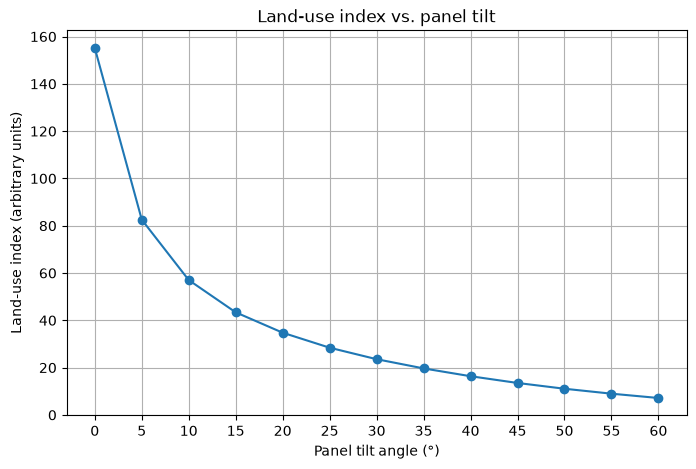

Table0: 317.0 262.0


In [20]:
#9. Land area usage vs needs

#a. Calculate needs and land area

N0 = np.ceil(Area0_0 / (L * W))
N5 = np.ceil(Area5_0 / (L * W))
N10 = np.ceil(Area10_0 / (L * W))
N15 = np.ceil(Area15_0 / (L * W))
N20 = np.ceil(Area20_0 / (L * W))
N25 = np.ceil(Area25_0 / (L * W))
N30 = np.ceil(Area30_0 / (L * W))
N35 = np.ceil(Area35_0 / (L * W))
N40 = np.ceil(Area40_0 / (L * W))
N45 = np.ceil(Area45_0 / (L * W))
N50 = np.ceil(Area50_0 / (L * W))
N55 = np.ceil(Area55_0 / (L * W))
N60 = np.ceil(Area60_0 / (L * W))

#b. Finding the nearest possible table (inverter voltage window - 24 panel string)

Table0 = np.ceil(N0 / 24)
Table5 = np.ceil(N5 / 24)
Table10 = np.ceil(N10 / 24)
Table15 = np.ceil(N15 / 24)
Table20 = np.ceil(N20 / 24)
Table25 = np.ceil(N25 / 24)
Table30 = np.ceil(N30 / 24)
Table35 = np.ceil(N35 / 24)
Table40 = np.ceil(N40 / 24)
Table45 = np.ceil(N45 / 24)
Table50 = np.ceil(N50 / 24)
Table55 = np.ceil(N55 / 24)
Table60 = np.ceil(N60 / 24)

#c. Find the updated count (To satisfy the 24 panel string many panels are added)

N0up = Table0 * 24
N5up = Table5 * 24
N10up = Table10 * 24
N15up = Table15 * 24
N20up = Table20 * 24
N25up = Table25 * 24
N30up = Table30 * 24
N35up = Table35 * 24
N40up = Table40 * 24
N45up = Table45 * 24
N50up = Table50 * 24
N55up = Table55 * 24
N60up = Table60 * 24

Area0 = np.floor(N0up * (L * W))
Area5 = np.floor(N5up * (L * W))
Area10 = np.floor(N10up * (L * W))
Area15 = np.floor(N15up * (L * W))
Area20 = np.floor(N20up * (L * W))
Area25 = np.floor(N25up * (L * W))
Area30 = np.floor(N30up * (L * W))
Area35 = np.floor(N35up * (L * W))
Area40 = np.floor(N40up * (L * W))
Area45 = np.floor(N45up * (L * W))
Area50 = np.floor(N50up * (L * W))
Area55 = np.floor(N55up * (L * W))
Area60 = np.floor(N60up * (L * W))

print(Area0, Area5, Area10,Area15,Area20,Area25,Area30,Area35,Area40,Area45,Area50,Area55,Area60)

#d. Calculate the energy density (efficiency of the area usage) !!!

#d.1 Calc real tilted panel area usage

L0 = L * math.cos(math.radians(0))
L5 = L * math.cos(math.radians(5))
L10 = L * math.cos(math.radians(10))
L15 = L * math.cos(math.radians(15))
L20 = L * math.cos(math.radians(20))
L25 = L * math.cos(math.radians(25))
L30 = L * math.cos(math.radians(30))
L35 = L * math.cos(math.radians(35))
L40 = L * math.cos(math.radians(40))
L45 = L * math.cos(math.radians(45))
L50 = L * math.cos(math.radians(50))
L55 = L * math.cos(math.radians(55))
L60 = L * math.cos(math.radians(60))

Land_A0 = Area0 * sh0 / (L0 * W)
Land_A5 = Area5 * sh5 / (L5 * W)
Land_A10 = Area10 * sh10 / (L10 * W)
Land_A15 = Area15 * sh15 / (L15 * W)
Land_A20 = Area20 * sh20 / (L20 * W)
Land_A25 = Area25 * sh25 / (L25 * W)
Land_A30 = Area30 * sh30 / (L30 * W)
Land_A35 = Area35 * sh35 / (L35 * W)
Land_A40 = Area40 * sh40 / (L40 * W)
Land_A45 = Area45 * sh45 / (L45 * W)
Land_A50 = Area50 * sh50 / (L50 * W)
Land_A55 = Area55 * sh55 / (L55 * W)
Land_A60 = Area60 * sh60 / (L60 * W)

Landen0 = sum(valueneed) / Land_A0
Landen5 = sum(valueneed) / Land_A5
Landen10 = sum(valueneed) / Land_A10
Landen15 = sum(valueneed) / Land_A15
Landen20 = sum(valueneed) / Land_A20
Landen25 = sum(valueneed) / Land_A25
Landen30 = sum(valueneed) / Land_A30
Landen35 = sum(valueneed) / Land_A35
Landen40 = sum(valueneed) / Land_A40
Landen45 = sum(valueneed) / Land_A45
Landen50 = sum(valueneed) / Land_A50
Landen55 = sum(valueneed) / Land_A55
Landen60 = sum(valueneed) / Land_A60

#d.1 Find energy density for a land area to find good tilt angle

EDland0 = (all0 + all_0) / Land_A0
EDland5 = (all5 + all_5) / Land_A5
EDland10 = (all10 + all_10) / Land_A10
EDland15 = (all15 + all_15) / Land_A15
EDland20 = (all20 + all_20) / Land_A20
EDland25 = (all25 + all_25) / Land_A25
EDland30 = (all30 + all_30) / Land_A30
EDland35 = (all35 + all_35) / Land_A35
EDland40 = (all40 + all_40) / Land_A40
EDland45 = (all45 + all_45) / Land_A45
EDland50 = (all50 + all_50) / Land_A50
EDland55 = (all55 + all_55) / Land_A55
EDland60 = (all60 + all_60) / Land_A60

print(Area0, Area5, Area10, Area15, Area20, Area25, Area30, Area35, Area40, Area45, Area50, Area55, Area60)
print(N0, N5, N10, N15, N20, N25, N30, N35, N40, N45, N50, N55, N60)
print(Land_A0, Land_A5, Land_A10, Land_A15, Land_A20, Land_A25, Land_A30, Land_A35, Land_A40, Land_A45, Land_A50, Land_A55, Land_A60)
print("Landen:", Landen0, Landen5, Landen10, Landen15, Landen20, Landen25, Landen30, Landen35, Landen40, Landen45, Landen50, Landen55, Landen60)
print("ED land:", EDland0, EDland5, EDland10, EDland15, EDland20, EDland25, EDland30, EDland35, EDland40, EDland45, EDland50, EDland55, EDland60)

#e. Energy density plot

tilts = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60]

EDland = [
    EDland0, EDland5, EDland10, EDland15, EDland20, EDland25, EDland30,
    EDland35, EDland40, EDland45, EDland50, EDland55, EDland60
]

plt.figure(figsize=(8,5))

plt.plot(tilts, EDland, marker='o')

plt.xlabel("Panel tilt angle (°)")
plt.ylabel("Land-use index (arbitrary units)")
plt.title("Land-use index vs. panel tilt")
plt.xticks(tilts)
plt.grid(True)

plt.show()

#So, we choose 0 tilt as a best.
print("Table0:", Table0, Table35)

### #10 Simple battery sizing with a loss iteration

**Why:** find how big the battery must be so that PV plus battery cover the demand every hour, including the battery's own losses.

**Model / source:** cumulative-balance sizing (a Rippl mass-curve type method) plus a rule-based hourly energy balance with constant efficiencies. Own implementation.

**Flow of the cell:**

$$E_{pv} \;\to\; d_t \;\to\; C_t \;\to\; E_{batt} \;\to\; E_{cap} \;\to\; \text{hourly simulation} \;\to\; \text{losses} \;\to\; p \;\to\; \text{rescale PV and repeat once}$$

**Symbols:** $D_t$ = demand; $P_{dc0}$ = DC power per m² (#5); $A_0$ = panel area (#9); $\eta_{op}, \eta_{in}, \eta_{mppt}$ = `efflossop`, `effin`, `effmppt`; $\eta_{ch} = \eta_{dis} = 0.95$; $SOC_{min} = 0.1\,E_{cap}$, $SOC_{max} = 0.9\,E_{cap}$.

#### Step 1: hourly balance

$$E_{pv,t} = \eta_{op}\,\eta_{in}\,\eta_{mppt}\,P_{dc0,t}\,A_0 \qquad (1)$$

$$d_t = E_{pv,t} - D_t \qquad (2)$$

#### Step 2: battery size from the cumulative balance

$$C_t = \sum_{i \le t} d_i \qquad (3)$$

$$E_{batt} = \max_t C_t - \min_t C_t \qquad (4)$$

$$E_{cap} = \frac{E_{batt}}{SOC_{max}/E_{cap} - SOC_{min}/E_{cap}} = \frac{E_{batt}}{0.9 - 0.1} \qquad (5)$$

Equation (4) overestimates the need if the lowest point of $C$ comes before the highest.

#### Step 3: hourly rules (start at 50 % SOC)

If $d_t \ge 0$ (surplus, charging):

$$E_{stored} = \min\!\left(d_t\,\eta_{ch},\; SOC_{max} - SOC\right), \qquad E_{curt} = d_t - \frac{E_{stored}}{\eta_{ch}} \qquad (6)$$

If $d_t < 0$ (deficit, discharging):

$$E_{drawn} = \min\!\left(\frac{\lvert d_t \rvert}{\eta_{dis}},\; SOC - SOC_{min}\right), \qquad E_{uns} = \lvert d_t \rvert - \eta_{dis}\,E_{drawn} \qquad (7)$$

#### Step 4: loss estimate and rescaling

$$n_{cyc} = \frac{\sum \lvert \Delta SOC \rvert}{SOC_{max} - SOC_{min}} \qquad (8)$$

$$L_{est} = n_{cyc}\,(SOC_{max} - SOC_{min}) \left( \frac{1}{\eta_{ch}} - 1 + 1 - \eta_{dis} \right) \qquad (9)$$

$$p = \frac{L_{est}}{\sum E_{pv}}, \qquad E_{pv,it} = (1+p)\,E_{pv}, \qquad A_{real} = (1+p)\,A_0 \qquad (10)$$

Then equations (2) to (7) are run again with $E_{pv,it}$.

#### Worked numbers (from the printed output)

| | Pass 1 | Pass 2 (after rescaling) |
|---|---|---|
| PV energy [kWh/yr] | 3,005,479 | about 3,425,600 |
| $E_{batt}$ [kWh] | 1,192,094 | 1,538,973 |
| $E_{cap}$ [kWh] | 1,490,117 | 1,923,716 |
| Unserved [kWh] | 140,088 | about 0 |
| Battery losses [kWh] | 209,609 | 234,319 |
| Equivalent cycles per year | 3.43 | 2.97 |
| Panel area [m²] | 15,201 | about 17,326 |

$p = 420{,}108 / 3{,}005{,}479 = 13.98\,\%$

About 3 cycles a year means the battery works as seasonal storage, which is why it is so large.

**Assumptions:**
1. $\eta_{ch} = \eta_{dis} = 0.95$, so the round trip is $0.95^2 = 0.9025$ [D].
2. No power limit, no temperature effects and no self-discharge. #11 adds those.
3. Only one iteration.

**To check:**
1. $L_{est}$ = 420,108 kWh is about twice the simulated loss (209,609 kWh). Equation (8) sums both up and down SOC moves, so each cycle is probably counted twice. PV may therefore be scaled up more than needed.
2. The comment "20 degree tilt" in section e should read 0°.
3. "Initial battery storage" prints the final `SOC_it`, because the loop changes it.

-660.938
2085.509352282624
6239
1192093.8362304214
Charging losses: 98348.81006210021 kWh
Discharging losses: 111260.07703281153 kWh
Total battery losses: 209608.88709491174 kWh
Unserved energy: 140087.56024323602 kWh
Curtailed energy: 7.62237495344209e-12 kWh
Final SOC: 388484.49816769216 kWh
3.4337527564025097
Equivalent full cycles: 3.4337527564025097
Estimated battery losses: 420107.5377521563 kWh
Actual simulated losses: 209608.88709491174 kWh
Initital battery storage: 388484.49816769216 kWh
            time  demand   unserved           SOC
2025-02-26T00:00 464.356 333.471723 149011.729529
2025-02-26T01:00 443.278 443.278000 149011.729529
2025-02-26T02:00 454.338 454.338000 149011.729529
2025-02-26T03:00 451.167 451.167000 149011.729529
2025-02-26T04:00 453.055 453.055000 149011.729529
2025-02-26T05:00 458.041 458.041000 149011.729529
2025-02-26T06:00 421.277 421.277000 149011.729529
2025-02-26T07:00 434.707 434.707000 149011.729529
2025-02-26T08:00 437.098 331.488312 149011.72952

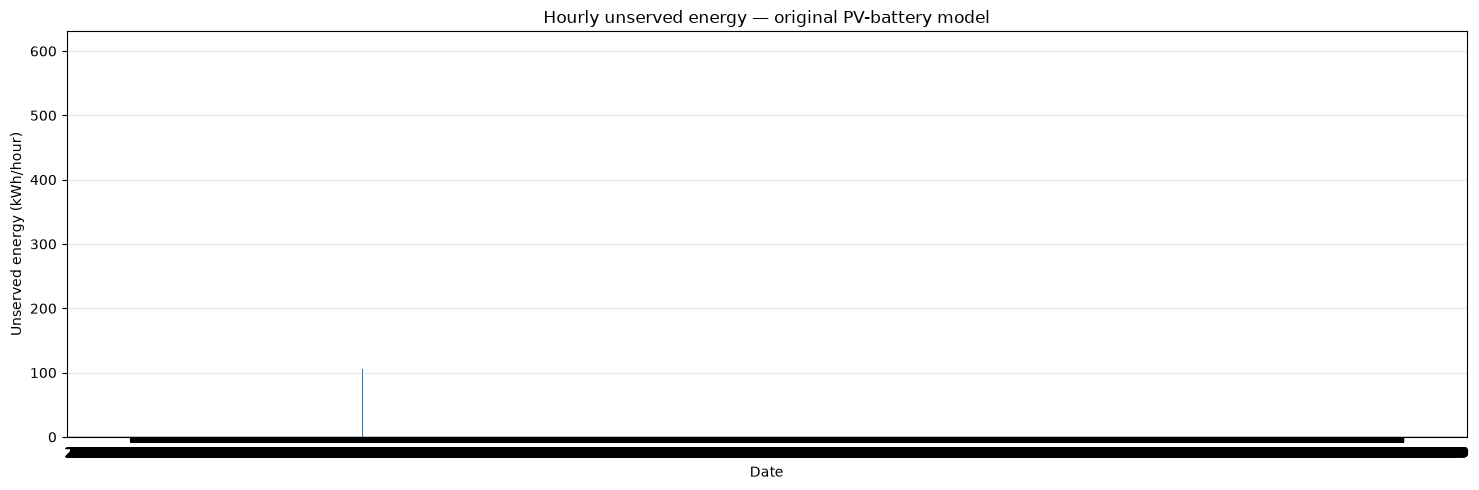

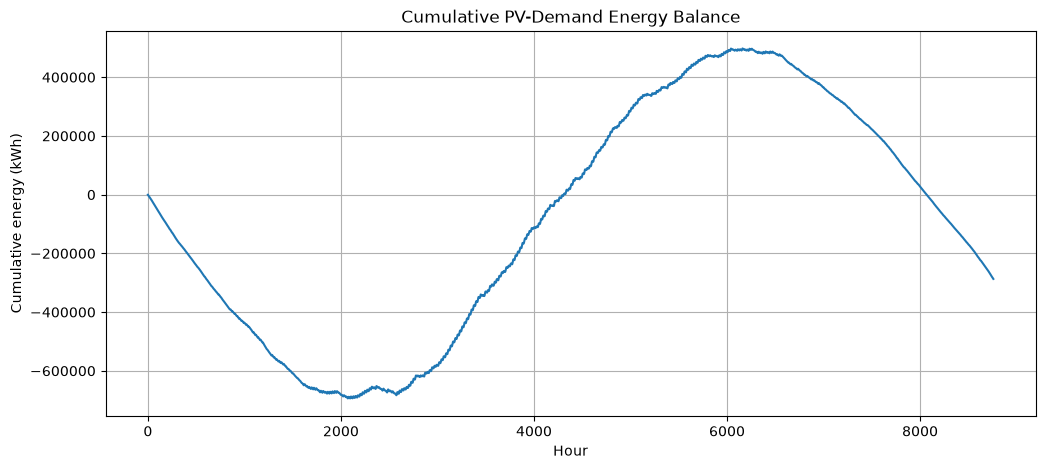

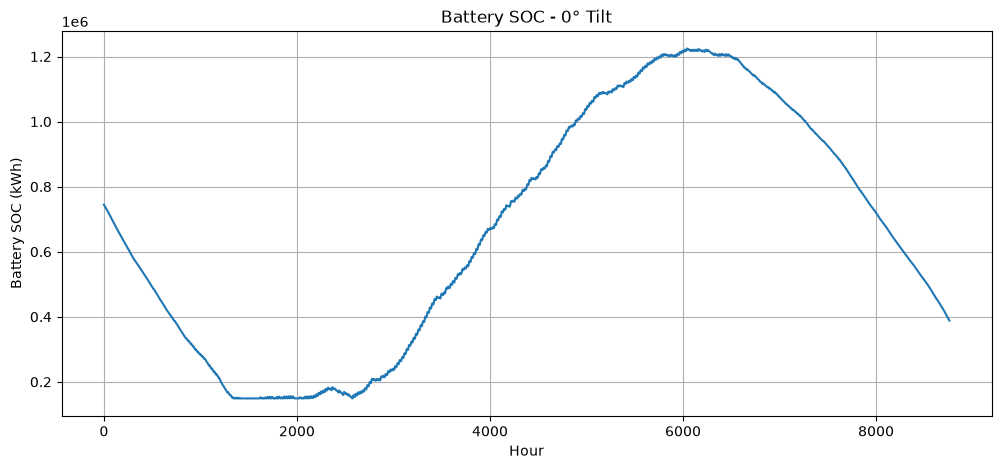

Initial choose production: 3005478.9523753496
Percentage loss: 0.13978056223622148
-660.938
2413.970453817534
6150
1538973.360366391
Charging losses: 117567.05076345793 kWh
Discharging losses: 116751.91053377118 kWh
Total battery losses: 234318.9612972291 kWh
Unserved energy: 5.7767124417296145e-12 kWh
Curtailed energy: 6.31406038564819e-12 kWh
Final SOC: 860594.1040592716 kWh
2.9684326298565935
Equivalent full cycles: 2.9684326298565935
Estimated battery losses: 468855.8179901951 kWh
Actual simulated losses: 234318.9612972291 kWh
Initial battery storage: 860594.1040592716 kWh
Empty DataFrame
Columns: [time, demand, unserved_it, SOC_it]
Index: []


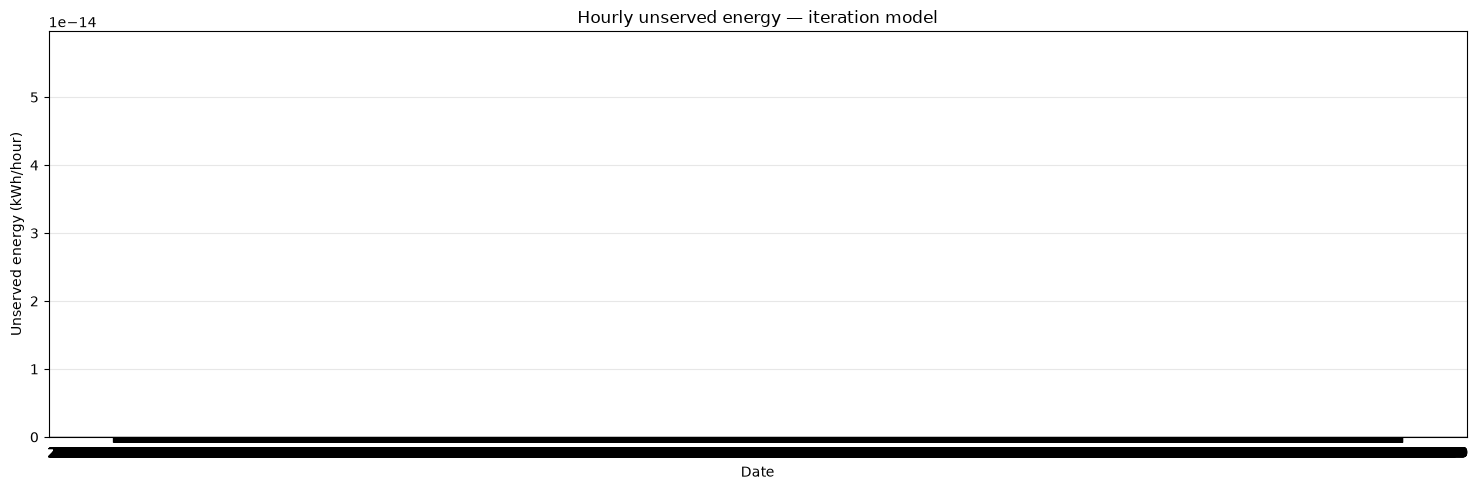

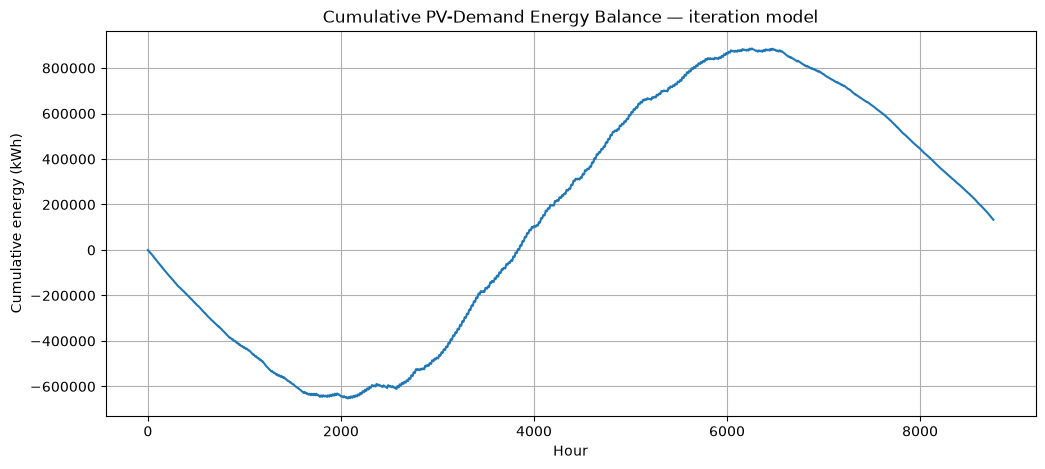

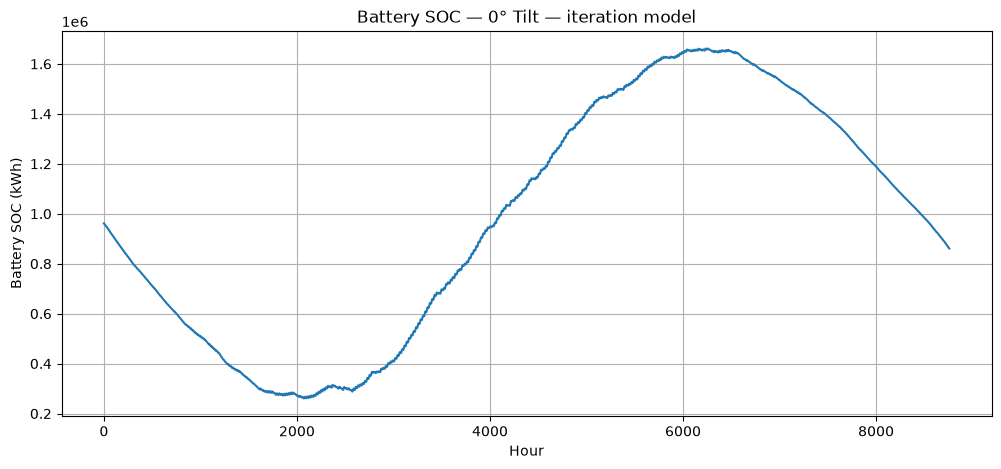

In [14]:
#10. Battery general simple sizing

#a. Calculate hourly difference in electiricity production

Epv = efflossop * effin * effmppt * Pdc0 * Area0

df["diff0"] = Epv - df["demand"]

print(df["diff0"].min())
print(df["diff0"].max())
print((df["diff0"] < 0).sum())

#b. Finding max battery storage for simplfied model

cumulative = df["diff0"].cumsum()
Ebatt = cumulative.max() - cumulative.min()


print(Ebatt)

#c. Use initial SOC and DOD values to calculate battery storage

SOC_min = 0.1
SOC_max = DOD = 0.9
usage = SOC_max - SOC_min

#c.1 Include SOC limitation and find the power

cycbatt = Ebatt / usage

#d. Add efficiencies

eff_disch = 0.95
eff_ch = 0.95

#e. Find battery size for 20 degree tilt

battcap = cycbatt
socmin = SOC_min * battcap
socmax = SOC_max * battcap

SOC = 0.5 * battcap

sochour = []
unserved = []
curtailed = []
charge_losses = []
discharge_losses = []

for balance in df["diff0"]:

    if balance >= 0:
        # Charging
        energy_to_batt = balance * eff_ch
        available_sp = socmax - SOC
        stored = min(energy_to_batt, available_sp)

        SOC += stored

        # Energy entering the battery, excluding curtailed energy
        energy_accepted = stored / eff_ch

        charge_losses.append(energy_accepted - stored)
        discharge_losses.append(0)

        curtailed.append(max(0, balance - energy_accepted))
        unserved.append(0)

    else:
        # Discharging
        energy_need = abs(balance) / eff_disch
        available_en = SOC - socmin
        discharged = min(energy_need, available_en)

        SOC -= discharged

        energy_delivered = discharged * eff_disch

        discharge_losses.append(discharged - energy_delivered)
        charge_losses.append(0)

        unserved.append(max(0, abs(balance) - energy_delivered))
        curtailed.append(0)

    sochour.append(SOC)

df["SOC"] = sochour
df["unserved"] = unserved
df["curtailed"] = curtailed
df["charge_loss"] = charge_losses
df["discharge_loss"] = discharge_losses

print("Charging losses:", df["charge_loss"].sum(), "kWh")
print("Discharging losses:", df["discharge_loss"].sum(), "kWh")
print("Total battery losses:",
      df["charge_loss"].sum() + df["discharge_loss"].sum(), "kWh")
print("Unserved energy:", df["unserved"].sum(), "kWh")
print("Curtailed energy:", df["curtailed"].sum(), "kWh")
print("Final SOC:", df["SOC"].iloc[-1], "kWh")

#f. Find the losses to set unserved energy to zero

delta_soc = df["SOC"].diff().abs()
cycles = delta_soc.sum() / (socmax - socmin)
print(cycles)
estimated_loss = cycles * (socmax - socmin) * ((1 / eff_ch - 1) + (1 - eff_disch))

actual_loss = (df["charge_loss"].sum() + df["discharge_loss"].sum())

print("Equivalent full cycles:", cycles)
print("Estimated battery losses:", estimated_loss, "kWh")
print("Actual simulated losses:", actual_loss, "kWh")
print("Initital battery storage:", SOC, "kWh")
# diff due to hourly fluctuation from the cycles * effloss

#g. Shows the dates of unserved energy

threshold = 1e-9  # kWh

unserved_hours = df.loc[
    df["unserved"] > threshold,
    ["time", "demand", "unserved", "SOC"]
].copy()

print(unserved_hours.to_string(index=False))

plt.figure(figsize=(15, 5))
plt.bar(df["time"], df["unserved"], width=0.03)

plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Date")
plt.ylabel("Unserved energy (kWh/hour)")
plt.title("Hourly unserved energy — original PV-battery model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


#h. Cumulative battery usage diagram

plt.figure(figsize=(12,5))

plt.plot(cumulative)

plt.xlabel("Hour")
plt.ylabel("Cumulative energy (kWh)")
plt.title("Cumulative PV-Demand Energy Balance")
plt.grid()

plt.show()
plt.figure(figsize=(12,5))

plt.plot(df["SOC"])

plt.xlabel("Hour")
plt.ylabel("Battery SOC (kWh)")
plt.title("Battery SOC - 0° Tilt")
plt.grid()

plt.show()


# i. Iteration

print("Initial choose production:", sum(Epv))
percentage_loss = estimated_loss / sum(Epv)
print("Percentage loss:", percentage_loss)
Epv_it = Epv * (1 + percentage_loss) 

Area_real = Area0 * (1 + percentage_loss)
df["diff0_it"] = Epv_it - df["demand"]

print(df["diff0_it"].min())
print(df["diff0_it"].max())
print((df["diff0_it"] < 0).sum())

# i.1 Finding max battery storage for simplified model

cumulative_it = df["diff0_it"].cumsum()
Ebatt_it = cumulative_it.max() - cumulative_it.min()

print(Ebatt_it)

# i.2 Use initial SOC and DOD values to calculate battery storage

SOC_min_it = 0.1
SOC_max_it = DOD_it = 0.9
usage_it = SOC_max_it - SOC_min_it

# i.2.1 Include SOC limitation and find the power

cycbatt_it = Ebatt_it / usage_it

# i.3 Add efficiencies

eff_disch_it = 0.95
eff_ch_it = 0.95

# i.4 Find battery size for 0 degree tilt

battcap_it = cycbatt_it
socmin_it = SOC_min_it * battcap_it
socmax_it = SOC_max_it * battcap_it

SOC_it = 0.5 * battcap_it

sochour_it = []
unserved_it = []
curtailed_it = []
charge_losses_it = []
discharge_losses_it = []

for balance_it in df["diff0_it"]:

    if balance_it >= 0:
        # Charging
        energy_to_batt_it = balance_it * eff_ch_it
        available_sp_it = socmax_it - SOC_it
        stored_it = min(energy_to_batt_it, available_sp_it)

        SOC_it += stored_it

        # Energy entering the battery, excluding curtailed energy
        energy_accepted_it = stored_it / eff_ch_it

        charge_losses_it.append(energy_accepted_it - stored_it)
        discharge_losses_it.append(0)

        curtailed_it.append(max(0, balance_it - energy_accepted_it))
        unserved_it.append(0)

    else:
        # Discharging
        energy_need_it = abs(balance_it) / eff_disch_it
        available_en_it = SOC_it - socmin_it
        discharged_it = min(energy_need_it, available_en_it)

        SOC_it -= discharged_it

        energy_delivered_it = discharged_it * eff_disch_it

        discharge_losses_it.append(discharged_it - energy_delivered_it)
        charge_losses_it.append(0)

        unserved_it.append(max(0, abs(balance_it) - energy_delivered_it))
        curtailed_it.append(0)

    sochour_it.append(SOC_it)

df["SOC_it"] = sochour_it
df["unserved_it"] = unserved_it
df["curtailed_it"] = curtailed_it
df["charge_loss_it"] = charge_losses_it
df["discharge_loss_it"] = discharge_losses_it

print("Charging losses:", df["charge_loss_it"].sum(), "kWh")
print("Discharging losses:", df["discharge_loss_it"].sum(), "kWh")
print("Total battery losses:",df["charge_loss_it"].sum() + df["discharge_loss_it"].sum(),
    "kWh")
print("Unserved energy:", df["unserved_it"].sum(), "kWh")
print("Curtailed energy:", df["curtailed_it"].sum(), "kWh")
print("Final SOC:", df["SOC_it"].iloc[-1], "kWh")

# i.5 Find the losses to set unserved energy to zero

delta_soc_it = df["SOC_it"].diff().abs()
cycles_it = delta_soc_it.sum() / (socmax_it - socmin_it)

print(cycles_it)

estimated_loss_it = cycles_it * (socmax_it - socmin_it) * (
    (1 / eff_ch_it - 1) + (1 - eff_disch_it))

actual_loss_it = (
    df["charge_loss_it"].sum()
    + df["discharge_loss_it"].sum())

print("Equivalent full cycles:", cycles_it)
print("Estimated battery losses:", estimated_loss_it, "kWh")
print("Actual simulated losses:", actual_loss_it, "kWh")
print("Initial battery storage:", SOC_it, "kWh")

# Difference due to hourly fluctuation from the cycles * efficiency loss

# i.6 Shows the dates of unserved energy

threshold_it = 1e-9  # kWh

unserved_hours_it = df.loc[df["unserved_it"] > threshold_it,
    ["time", "demand", "unserved_it", "SOC_it"]].copy()

print(unserved_hours_it.to_string(index=False))

plt.figure(figsize=(15, 5))
plt.bar(df["time"], df["unserved_it"], width=0.03)

plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Date")
plt.ylabel("Unserved energy (kWh/hour)")
plt.title("Hourly unserved energy — iteration model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# i.7 Cumulative battery usage diagram

plt.figure(figsize=(12, 5))
plt.plot(cumulative_it)

plt.xlabel("Hour")
plt.ylabel("Cumulative energy (kWh)")
plt.title("Cumulative PV-Demand Energy Balance — iteration model")
plt.grid()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(df["SOC_it"])

plt.xlabel("Hour")
plt.ylabel("Battery SOC (kWh)")
plt.title("Battery SOC — 0° Tilt — iteration model")
plt.grid()
plt.show()


### #11 Battery temperature, efficiency and self-discharge

**Why:** the battery is in a cold climate. Temperature changes how fast it heats or cools, whether charging is allowed, how efficient it is and how fast it leaks energy.

**Model / source:** my own implementation of a lumped-capacitance (Newton cooling) thermal model with exact hourly update, a linear efficiency-temperature rule and Arrhenius self-discharge. Tags: [A] manufacturer-published (LVFU), [C] proxy data (EVE cell), [D] my assumption.

**Formulas:**

$$\tau = \frac{C_{th}}{UA},\quad a = e^{-\Delta t/\tau},\quad T_{eq} = T_a + \frac{Q}{UA},\quad T_{b,t+1} = T_{eq} + (T_{b,t} - T_{eq})\,a$$

- Heat Q = P_ch (1 - eta) + P_dis (1/eta - 1), the conversion losses.
- Round-trip efficiency, linear in temperature: 0.95 at 25 °C or above, 0.76 at 5 °C or below; eta = sqrt of it.
- Self-discharge per hour: r(T) = r25 exp[(Ea/R)(1/298.15 - 1/(T + 273.15))], where r25 comes from 3 % per month.
- Charging is blocked below 1 + 2 °C and allowed again above 1 + 2 + 2 °C (margin and hysteresis).

**Assumptions:**
1. LVFU: charging only above 1 °C [A]; 240 kWh available per cabinet [A].
2. Per cabinet, C_th = 0.5 kWh/K and UA = 15 W/K [D]; the cabinet count is N = ceil(E_max / 240) (about 7,200 here) and the totals scale with it.
3. Round trip 0.95 and 3 %/month are EVE proxy values [C], used as a sensitivity. Ea = 40 kJ/mol [D].
4. PCS total 125 kW x ceil(peak / 125) = 750 kW [D].
5. Chiller holds the cells to 25 °C or below; its electricity is not counted. No heater is modelled.
6. #10 uses 0.95 x 0.95 = 0.9025 round trip. For comparison, set `eta_rt_25 = eff_ch_it * eff_disch_it`.

**Expect:** results differ from #10 because of the power limit, temperature and leakage.

**Check:** the printed line shows cabinets, PCS 750 kW and tau = 33.3 h.

**First result (depends on the [D] assumptions above):** 7,214 cabinets; the battery temperature stays between 1.6 °C and 18.5 °C; charging is blocked in 21 hours of the year.

In [15]:
#11. Battery temperature dependency
#0. Link to the earlier cells
T_a     = temp0                          # hourly ambient [°C], 8760 values, index reset
P_load  = df["demand"]                   # kWh per hour (= kW)
P_pv    = pd.Series(np.asarray(Epv_it))  # PV used by the final iteration model of #10
E_max   = socmax_it                      # kWh
E_min   = socmin_it                      # kWh
E_start = 0.5 * battcap_it               # where #10 starts its SOC_it
assert len(T_a) == len(P_load) == len(P_pv)

#a. Limits and size
T_ch_min = 1.0           # charge only above this [°C]
T_margin = 2.0           # [D] Tb is an average; the limit applies to the coldest cell
T_hyst   = 2.0           # [D] stops on/off flipping every hour
assert T_a.between(-30, 50).all()          # ambient limits
E_cab    = 240.0                                     # kWh available per LVFU cabinet [A: datasheet]
N_cab    = int(np.ceil(E_max / E_cab))               # [D] cabinets needed for your battery
P_pcs    = 125.0 * np.ceil(peak_power_need / 125.0)  # [D] kW, total PCS: 125 kW modules covering your peak demand

#b. Thermal model  (per cabinet [D] until LVFU answers, times N_cab)
C_th   = 1.8e6 * N_cab   # J/K  (= 0.5 kWh/K per cabinet)
UA     = 15.0 * N_cab    # W/K  per cabinet 15
tau    = C_th / UA / 3600        # hours -> 33.3 h (does not depend on N_cab)
del_t  = 1.0
a_th   = np.exp(-del_t / tau)    # 0.9704
T_b0   = 8.2
T_cool = 25.0            # [D] chiller keeps cells at 25 °C or below; its electricity is NOT counted

#c. Loss parameters
eta_rt_25, eta_rt_5 = 0.95, 0.76     # round trip at 25 °C and at <=5 °C  [C: EVE minimum, sensitivity only]
SD_month = 0.03                      # per month at 25 °C                 [C: EVE upper bound]
Ea, Rgas = 40e3, 8.314               # J/mol, J/(mol K)                   [D]
r25 = 1 - (1 - SD_month)**(1/720)    # per hour at 25 °C = 4.23e-5

def eta_rt(T):                       # LINEAR in T, clipped
    return np.clip(eta_rt_5 + (eta_rt_25 - eta_rt_5)*(T - 5)/20, eta_rt_5, eta_rt_25)

def r_sd(T):                         # Arrhenius: colder -> slower leak
    return r25*np.exp(Ea/Rgas*(1/298.15 - 1/(T + 273.15)))

#d. Hourly loop
n_h = len(T_a)
T_b = np.zeros(n_h + 1);  T_b[0] = T_b0
E   = np.zeros(n_h + 1);  E[0]   = E_start
Pch_h, Pdis_h, curt_h, uns_h = (np.zeros(n_h) for _ in range(4))
blocked = np.zeros(n_h, dtype=bool)
ok_ch = True

for t in range(n_h):
    Tb = T_b[t]                                   # start-of-hour temperature

    # 1. charge permission, with margin + hysteresis
    if   Tb < T_ch_min + T_margin:              ok_ch = False
    elif Tb > T_ch_min + T_margin + T_hyst:     ok_ch = True

    # 2. efficiency from temperature (same for charge and discharge)
    eta = np.sqrt(eta_rt(Tb))

    # 3. self-discharge first
    Ee = E[t] * (1 - r_sd(Tb))

    # 4. YOUR dispatch goes here: use eta, and force P_ch = 0 if not ok_ch
    net = P_pv.iloc[t] - P_load.iloc[t]
    if net >= 0:
        P_ch  = min(net, P_pcs, (E_max - Ee)/(eta*del_t)) if ok_ch else 0.0
        P_dis = 0.0
        Ee   += eta*P_ch*del_t                    # P_ch is the converter-side power
        curt_h[t]  = net - P_ch
        blocked[t] = (not ok_ch) and net > 0
    else:
        P_dis = min(-net, P_pcs, max((Ee - E_min)*eta/del_t, 0))
        P_ch  = 0.0
        Ee   -= P_dis/eta*del_t
        uns_h[t]   = -net - P_dis
    E[t+1] = Ee
    Pch_h[t], Pdis_h[t] = P_ch, P_dis

    # 5. losses become heat, then update the temperature (end of hour)
    q_gen    = P_ch*(1 - eta) + P_dis*(1/eta - 1)         # kW
    T_eq     = T_a.iloc[t] + q_gen*1000/UA
    T_b[t+1] = min(T_eq + (T_b[t] - T_eq)*a_th, T_cool)

print("cabinets:", N_cab, "| PCS [kW]:", P_pcs, "| tau [h]:", round(tau, 1))
print("T_b min / max [°C]:", round(T_b.min(), 1), round(T_b.max(), 1), "| hours charge blocked:", int(blocked.sum()))

cabinets: 7214 | PCS [kW]: 750.0 | tau [h]: 33.3
T_b min / max [°C]: 1.6 18.5 | hours charge blocked: 21


### #12 Four critical weeks

**Why:** look closely at the weeks that stress the system most: highest and lowest demand, highest and lowest generation.

**Model / source:** my own data analysis: daily sums, rolling 7-day sums and bar plots.

**Logic:**
1. Daily demand and daily generation, then rolling 7-day sums.
2. Find the week with the highest and lowest demand and the highest and lowest generation.
3. Plot each week hour by hour: PV and battery discharge above zero, demand and battery charging below zero. The battery is inferred from the change in SOC.

**Assumptions:** the battery is the first-pass battery from #10 (`SOC`), not the iteration.

**To check:**
1. **Battery signs look inverted.** A rising SOC means charging, but `soc_change.clip(lower=0)` is labelled "discharge". The fix is:
   `week["battery_discharge"] = (-soc_change).clip(lower=0)`
   `week["battery_charge"] = (-soc_change).clip(upper=0)`
2. Three different PV definitions are used: `generation0` is raw `Pdc0 x Area0`, the plot uses `efflossop x effin x Pdc0 x Area0` (no `effmppt`), and #10 uses all three factors.
3. The week end dates are typed in by hand. If inputs change, they must be updated.

Peak 7-day demand: 94239.204 ending 2025-02-21 00:00:00
Least 7-day demand: 39501.915 ending 2025-07-22 00:00:00
Peak 7-day generation: 167411.2214916 ending 2025-05-23 00:00:00
Least 7-day generation: 3602.38283928 ending 2025-12-12 00:00:00


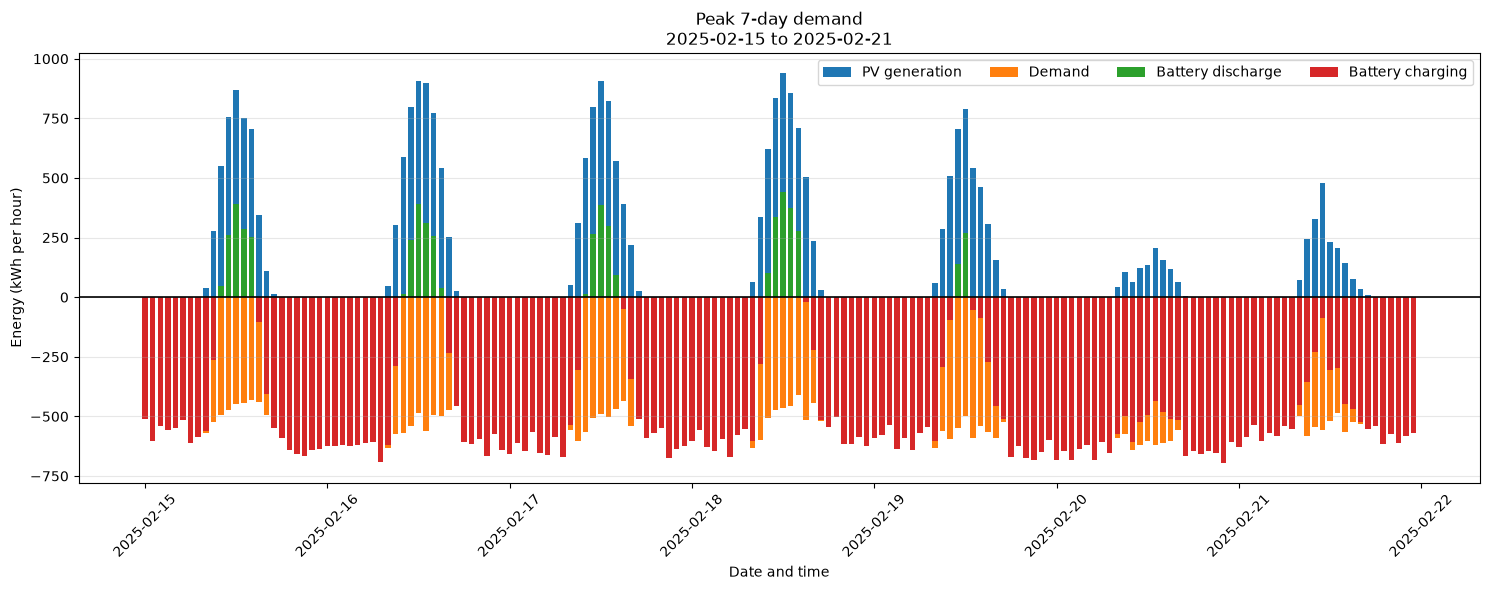

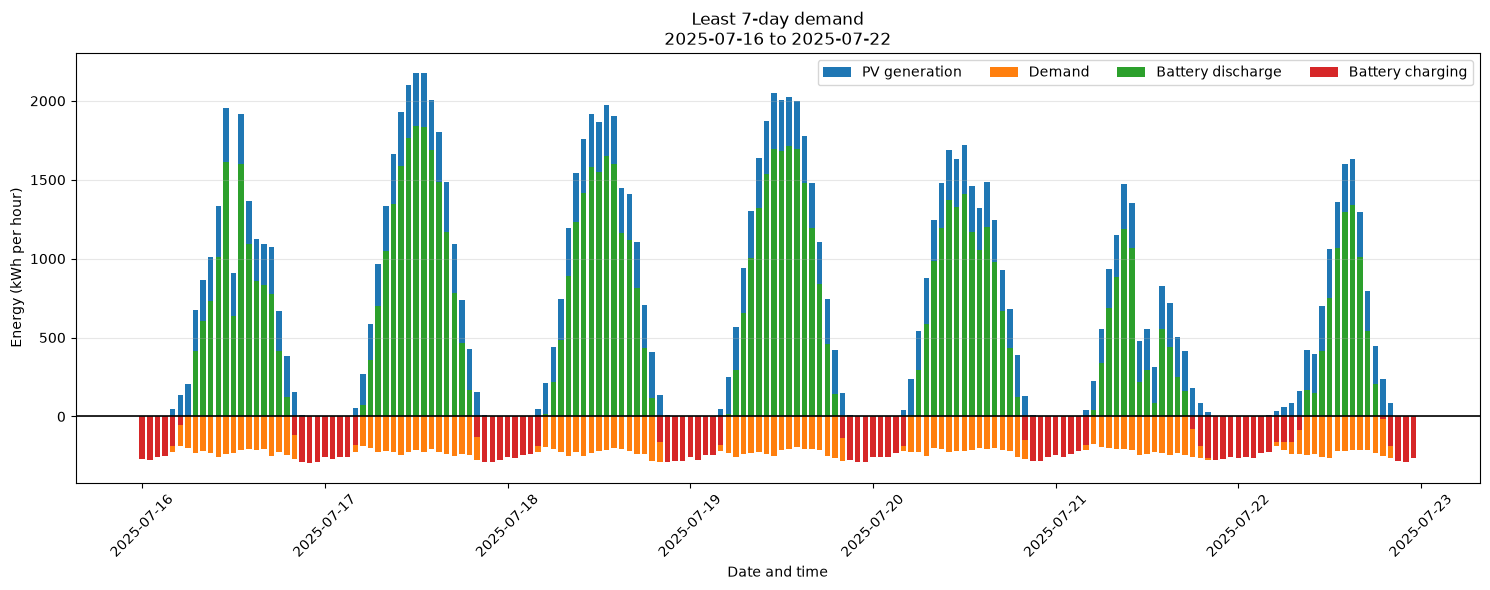

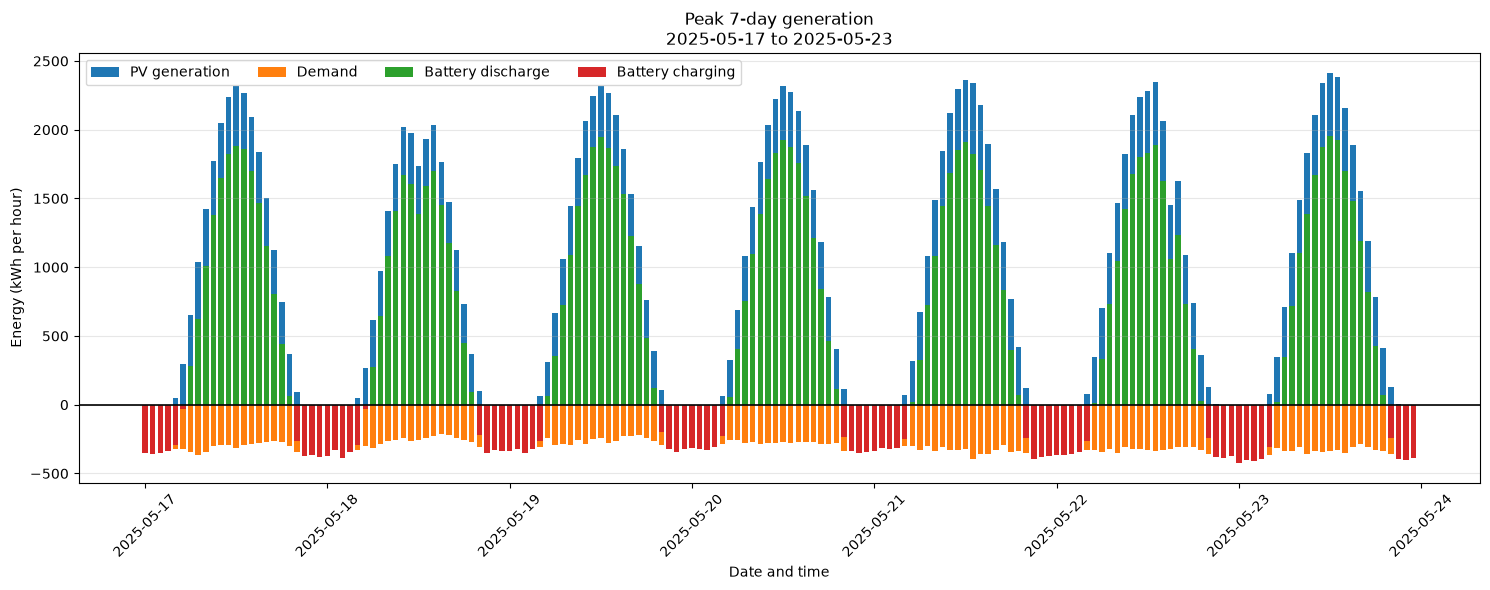

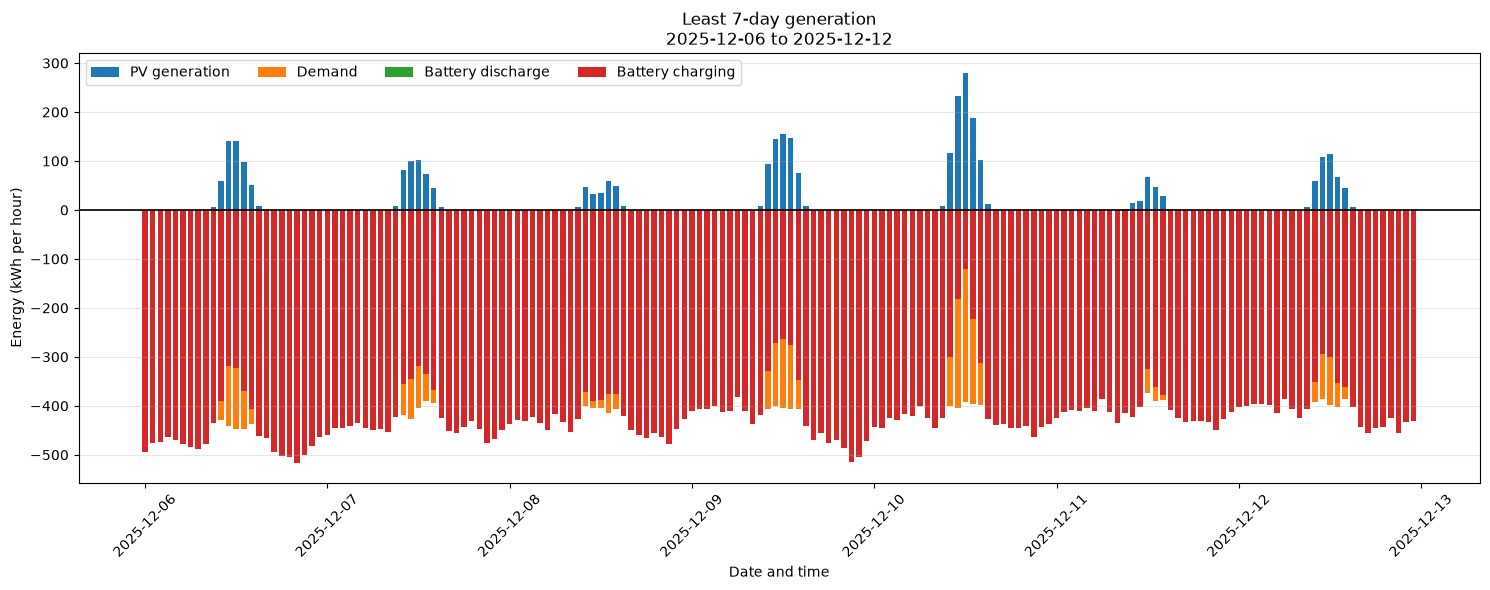

In [16]:
#12. See whether the battery can satisfy the demand for peak and least needs for a week

#a. Group the data by day and calculate daily demand and generation

df["time"] = pd.to_datetime(df["time"])
hourly = df.assign(generation0=np.asarray(Pdc0 * Area0))
groups = np.arange(len(hourly)) // 24

daily = hourly.groupby(groups).agg(
    date=("time", "first"),
    daily_demand=("demand", "sum"),
    daily_generation=("generation0", "sum"),
)
daily["date"] = daily["date"].dt.normalize()

#b. Calculate rolling 7-day sums for demand and generation

rolling_7 = daily[["daily_demand", "daily_generation"]].rolling(7).sum().dropna()
rolling_7["date"] = daily.loc[rolling_7.index, "date"]

peak_demand = rolling_7.loc[rolling_7["daily_demand"].idxmax()]
least_demand = rolling_7.loc[rolling_7["daily_demand"].idxmin()]
peak_generation = rolling_7.loc[rolling_7["daily_generation"].idxmax()]
least_generation = rolling_7.loc[rolling_7["daily_generation"].idxmin()]

print("Peak 7-day demand:", peak_demand["daily_demand"], "ending", peak_demand["date"])
print("Least 7-day demand:", least_demand["daily_demand"], "ending", least_demand["date"])
print("Peak 7-day generation:", peak_generation["daily_generation"], "ending", peak_generation["date"])
print("Least 7-day generation:", least_generation["daily_generation"], "ending", least_generation["date"])

#c. Graph

plot_df = df.copy().reset_index(drop=True)
plot_df["time"] = pd.to_datetime(plot_df["time"])

plot_df["pv_generation"] = np.asarray(efflossop * effin * Pdc0 * Area0)

# Define the four seven-day windows by their ending dates
periods = {
    "Peak 7-day demand": "2025-02-21",
    "Least 7-day demand": "2025-07-22",
    "Peak 7-day generation": "2025-05-23",
    "Least 7-day generation": "2025-12-12",
}

for title, end_date in periods.items():
    end_date = pd.Timestamp(end_date)

    # Seven calendar days, including the ending date
    start_date = end_date - pd.Timedelta(days=6)

    week = plot_df[
        (plot_df["time"] >= start_date) &
        (plot_df["time"] < end_date + pd.Timedelta(days=1))].copy()

    if len(week) == 0:
        print(f"No data found for {title}")
        continue

    # Positive = PV generation / battery discharging
    # Negative = demand / battery charging
    week["demand_component"] = -week["demand"]

    # Infer battery charging/discharging from the SOC change
    soc_change = week["SOC"].diff()
    first_idx = week.index[0]

    if first_idx > 0:
        soc_change.iloc[0] = plot_df.loc[first_idx, "SOC"] - plot_df.loc[first_idx - 1, "SOC"]
    else:
        soc_change.iloc[0] = 0

    week["battery_discharge"] = soc_change.clip(lower=0)
    week["battery_charge"] = soc_change.clip(upper=0)

    # Four component bar charts on a shared zero axis
    fig, ax = plt.subplots(figsize=(15, 6))

    ax.bar(
        week["time"], week["pv_generation"],
        width=0.03, label="PV generation")
    ax.bar(
        week["time"], week["demand_component"],
        width=0.03, label="Demand")
    ax.bar(
        week["time"], week["battery_discharge"],
        width=0.03, label="Battery discharge")
    ax.bar(
        week["time"], week["battery_charge"],
        width=0.03, label="Battery charging")

    ax.axhline(0, color="black", linewidth=1.2)
    ax.set_title(
        f"{title}\n{start_date.date()} to {end_date.date()}")
    ax.set_ylabel("Energy (kWh per hour)")
    ax.set_xlabel("Date and time")
    ax.legend(ncol=4)
    ax.grid(axis="y", alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [17]:
#13. Inverter choosing and sizing

In [18]:
#15. Panel figures and plots (divide and make it easy to see for hourly)
